# ONNX·TensorRT Day 3 — 강사용 노트북

**이 파일은 강사 전용입니다 (학생 배포 · GitHub 업로드 금지).** 학생용 `OT_Day3_lecture.ipynb` 와 셀 순서가 같고, 다음이 더해져 있습니다.

- 모든 빈칸이 **정답으로 채워져** 있고, 🔒 정답 보기 셀은 뺐습니다. 8교시 과제 6 모범 답안은 강사 노트 상자로 바꿔 넣었습니다.
- 코드 셀 아래 출력은 **강사 사전 실행 결과** — 서버 **CPU 2코어, GPU 없음** (PyTorch 2.15 · ONNX 1.23 · ONNX Runtime 1.29 CPU 판). 읽는 법:
  - **같아야 하는 것**: 노드 수 (mnv3s 127 · SimpleConvNet 레벨별 7/7/5/6), 레벨별 op 목록, 레벨 간 결과 차이 ≈ 0, profiling 1위 (mnv3s = Conv, SimpleConvNet = FusedGemm), 채점 90/90.
  - **다른 것 — 정상**: 모든 **시간 숫자** (Colab CPU 는 보통 2코어지만 장비가 다름), 스레드 · 배치 표의 최선 값 (1 스레드냐 2 스레드냐는 실행마다 바뀔 수 있음).
  - **여기 없는 것**: **5교시 GPU 출력** — 서버에 GPU 가 없어 `GPU 없음 — 건너뜀` 으로 찍혀 있습니다. 1-2 · 5교시 · 과제 5 의 GPU 줄은 **수업 전 Colab T4 에서 직접 돌려** 숫자를 확인해 두세요 (아래 체크리스트). 환경 셀의 '설치된 실행기' 도 Colab GPU 판에서는 `TensorrtExecutionProvider`, `CUDAExecutionProvider`, `CPUExecutionProvider` 로 나옵니다.
- 각 교시 · 문제 앞에 주황색 **👩‍🏫 강사 노트** — 시간 배분, 핵심 메시지, 판서 포인트, 예상 질문과 답, 자주 나는 오류, 실행 예 숫자.

### 하루 운영 요약

| 교시 | 시간 | 핵심 메시지 (한 줄) | 노트북 | 애니메이션 |
|---|---|---|---|---|
| 1 | 09:00–09:50 | providers 는 희망 목록 — 실제는 `get_providers()` | 퀴즈 15분 + 1-1 · 1-2 | D3-1 |
| 2 | 10:00–10:50 | 한 번 재면 안 된다: warm-up · n번 · **p95** | 2-1 ~ 2-3 · 🔁 PyTorch | D3-2 |
| 3 | 11:00–11:50 | 스레드는 코어 수까지. 넘으면 p95 부터 나빠진다 | 3-1 · 3-2 · make_session | D3-3 |
| 4 | 13:00–13:50 | ORT 는 세션을 만들 때 그래프를 고친다 — 합치기 · 레이아웃 | 4-1 · 4-2 · 🔁 allclose | D3-4 |
| 5 | 14:00–14:50 | GPU = 복사 + 첫 실행 비용. 일이 많아야 이긴다 | 5-1 ~ 5-3 | D3-5 |
| 6 | 15:00–15:50 | 지연 ≠ 처리량. 카메라 수 = 처리량 ÷ 30 | 6-1 ~ 6-3 | D3-6 |
| 7 | 16:00–16:50 | 어디가 느린지 재 본다 — 병목은 모델마다 다르다 | 7-1 ~ 7-3 | D3-7 |
| 8 | 17:00–17:50 | 조건 + 결과 표로 설정을 결정 — 90 + 10 | 과제 1 ~ 6 · 채점 셀 | D3-8 |

### 수업 전 체크리스트

- [ ] 저장소 `AI_CAMPUS/OT-day3/` 에 **`data/`** (`mnist_cnn.pt` · `mnist_sample.npz`) · `img/` · `animation.html` · `worksheet.html` · `OT_Day3.pdf` 업로드. `fetch()` 는 OT-day3 경로에서 받습니다.
- [ ] **Day 2 복습 퀴즈 만들기**: `OT_Day2_복습퀴즈_GoogleForm.gs` 를 [script.google.com](https://script.google.com) 새 프로젝트에 붙여 넣고 `createOTDay2Quiz` 실행 → 로그의 **응답 링크**를 09:00 에 공유 (20문항, 15분).
- [ ] 강사 Colab 에서 **런타임 유형 T4 GPU** 로 학생용 노트북을 처음부터 끝까지 한 번 실행 (약 5분). 특히:
    - [ ] 설치 셀 → 환경 셀의 '설치된 실행기' 에 `CUDAExecutionProvider` 가 있는지.
    - [ ] 1-2 가 `GPU 사용 가능 ✨` 를 출력하는지. 아니면: ① 설치 셀 후 **런타임 재시작 없이** 환경 셀을 실행했는지 (onnxruntime 을 이미 import 한 상태면 *런타임 → 세션 다시 시작* 후 환경 셀부터), ② `ort.preload_dlls()` 가 있는 환경 셀인지, ③ Colab 의 CUDA 12/13 과 onnxruntime-gpu 판이 맞는지 (오류 로그에 `libcudnn` · `libcublas` 가 보이면 판 불일치).
    - [ ] 5-1 · 5-2 · 5-3 의 **GPU 숫자**를 메모 (첫 실행 ms, 배치 1 · 32 의 fps, GPU vs CPU 최대 차이). 수업 중 '실행 예' 로 씁니다.
- [ ] **T4 할당 실패 대비**: 사용량 제한으로 GPU 를 못 받는 학생이 나옵니다. 1-2 확인 셀은 GPU 없이도 ✅ 이고 채점도 GPU 와 무관하니, "5교시는 강사 화면으로 본다" 고 미리 말해 두세요.
- [ ] 워크시트 · 애니메이션 링크 공지, 8교시 제출 방법 공지 (`ot_baseline.csv` 는 Day 4 에서 다시 씀 → Drive 저장 안내).

### 오늘 자주 나는 문제 (전체)

| 증상 | 원인 · 해결 |
|---|---|
| 환경 셀 `ImportError: onnxruntime` 또는 실행기 목록이 CPU 뿐 | 설치 셀 이전에 onnxruntime 을 import 함 → *런타임 → 세션 다시 시작* 후 환경 셀부터 (설치는 다시 안 해도 됨) |
| `get_providers()` 가 CPU 만 | 런타임 유형이 CPU · GPU 할당 실패 · CUDA 라이브러리 불일치. 1-2 출력으로 확인 |
| 시간 숫자가 옆 사람과 다름 | 정상. 장비 · 다른 작업 · 측정 오차. **같은 노트북 안에서** 비교 |
| 2-1 첫 실행이 별로 느리지 않음 | 같은 모델을 1-1 에서 이미 돌려 캐시가 데워진 경우. 5교시 GPU 첫 실행에서 확실히 보임 |
| 3-1 스레드 4 가 엄청 느리거나 p95 가 튐 | 정상 (과밀). Colab 이 코어 2개 → 설명 포인트 |
| 3교시 이후 `NameError: make_session` | '세션 만들기 도구' 셀을 건너뜀 |
| 4-1 경고 `Serializing optimized model ... hardware specific` | 정상 — ALL 레벨 저장 경고. 4교시 핵심 내용 |
| 5교시 `Failed to allocate memory` | GPU 메모리 부족 — 다른 Colab 탭 종료, 배치 32 → 16 |
| 7-1 노드 기록 0개 | `end_profiling()` 전에 파일을 읽음 / profile=True 빠짐 |
| 8교시 과제 2 ❌ | `best` 를 mean 기준으로 고름 → **p95** 의 `idxmin` |
| 과제 3 `chosen_batch` 가 None | Colab CPU 가 120 장/초에 못 미침 — 정답 처리됨 (채점은 일관성만). 과제 6 에서 대안 쓰게 하기 |
| 런타임 끊김 후 `NameError` | 환경 셀 → 1-1 (모델 · `x1` · `xm`) → 1-2 (`GPU_OK`) → 2-3 (`bench`) → `make_session` 셀 → 필요한 셀. 8교시는 과제 1 → 2 → 3 → 4 → 5 순서 |

<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/OT-day3/OT_Day3_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# [강사용] ONNX·TensorRT Day 3 — ONNX Runtime 으로 빠르게: 제대로 재고, 하나씩 바꿔 비교하기

**온디바이스 AI · ONNX·TensorRT 3/5 · 11/6(금)** · Google Colab (**T4 GPU 런타임 필수**) · ONNX Runtime (CPU · CUDA) · onnxslim

어제 5교시에 '1장씩 100번 vs 100장 1번' 을 **느낌만** 봤습니다. 오늘은 "빠르다" 를 **숫자로** 말합니다. 측정 함수 `bench()` 하나를 만들고, ONNX Runtime 의 손잡이를 **한 번에 하나씩** 돌려 가며 성능표에 줄을 쌓습니다.

> 4단계 중 오늘은 **실행하기**를 빠르게. 손잡이 다섯 개: **스레드 수 · 최적화 레벨 · CPU/GPU · 배치 크기**, 그리고 어디가 느린지 보는 **profiling**.

오늘의 목표

1. warm-up · 반복 측정 · **평균 · p50 · p95 · FPS** 로 추론 시간을 재는 `bench()` 를 만든다.
2. `SessionOptions` 로 **스레드 수**를 바꾸고, 코어 수와의 관계를 설명한다.
3. **그래프 최적화 레벨** 4단계의 차이를 노드 (`FusedConv` · `FusedGemm`) 와 시간으로 확인한다.
4. **CUDAExecutionProvider** 로 GPU 에서 실행하고, 복사 시간 · 첫 실행 · 결과 차이를 설명한다.
5. **배치 크기**에 따른 지연 (ms) 과 처리량 (장/초) 을 구분하고, 상황에 맞는 배치를 고른다.
6. **profiling** 으로 연산 종류별 시간 비율을 구해 병목을 찾는다.

| 교시 | 시간 | 주제 |
|---|---|---|
| 1 | 09:00–09:50 | Day 2 복습 퀴즈 · 오늘의 모델 · GPU 확인 |
| 2 | 10:00–10:50 | 시간을 재는 법 — warm-up · 평균 · p95 · FPS → `bench()` |
| 3 | 11:00–11:50 | 스레드 수 — `SessionOptions` · 한 번에 하나만 |
| 4 | 13:00–13:50 | 그래프 최적화 레벨 — 노드 합치기 · 레이아웃 |
| 5 | 14:00–14:50 | CPU → GPU — `CUDAExecutionProvider` |
| 6 | 15:00–15:50 | 배치 크기 — 지연 vs 처리량 |
| 7 | 16:00–16:50 | profiling — 어디가 느린가 |
| 8 | 17:00–17:50 | 미니 프로젝트 — 현장 카메라 4대용 설정 정하기 · 채점 |

**노트북 사용법**

1. *런타임 → 런타임 유형 변경 → **T4 GPU*** 를 꼭 고르세요 (5교시). *파일 → Drive에 사본 저장* 후 사본에서 작업합니다.
2. `____` 가 있는 셀은 빈칸을 채운 뒤 실행하고, 아래 **확인 셀**이 `✅` 를 출력하면 정답입니다.
3. 막히면 **🔒 정답 보기** 셀을 실행하세요. 🖼 그림 셀은 실행하지 않아도 그림이 보입니다.
4. 오늘은 **시간 숫자가 사람마다, 실행마다 다릅니다.** 확인 셀은 숫자 값이 아니라 **방법**을 검사합니다. 옆 사람과 숫자가 달라도 정상입니다.
5. 8교시 미니 프로젝트는 이 노트북 끝에 있습니다. 채점 셀 결과가 보이는 상태로 제출합니다.

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 8개) | [https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/animation.html) |
| 📝 개념 워크시트 (8교시 × 10문항) | [https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/worksheet.html](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/worksheet.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/OT_Day3.pdf](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/OT_Day3.pdf) |

**오늘의 모델** — **MobileNetV3-Small** (입력 224, 배치 자유, opset 17) 과 어제의 **SimpleConvNet** (`mnist_cnn_dyn.onnx`). MobileNetV3 는 **가중치를 내려받지 않고 구조만** 만듭니다 — 속도는 가중치 **값**과 상관없이 **구조**(연산 종류 · 크기) 로 정해지기 때문입니다.

In [ ]:
# ▶ 설치 셀 — GPU 용 ONNX Runtime. 처음 한 번, 약 1분
# CPU 판 onnxruntime 과 GPU 판 onnxruntime-gpu 는 같이 깔면 충돌하므로 CPU 판을 먼저 지운다
%pip uninstall -y -q onnxruntime
%pip install -q onnx onnxscript onnxslim onnxruntime-gpu

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요
import os, time, json, inspect, warnings, collections, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import onnx
import onnxruntime as ort

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 2)
torch.manual_seed(0)
BASE = "https://imguru-mooc.github.io/AI_CAMPUS/OT-day3"
RAW = "https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day3"
EXPORT_KW = {"dynamo": False} if "dynamo" in inspect.signature(torch.onnx.export).parameters else {}
CPU = ["CPUExecutionProvider"]
try:
    ort.preload_dlls()              # ORT 1.21+: PyTorch 가 깔아 둔 CUDA · cuDNN 을 먼저 불러온다 (GPU 판에서 필요)
except Exception:
    pass

def fetch(name):
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        for url in [f"{BASE}/data/{name}", f"{RAW}/data/{name}"]:
            try:
                urllib.request.urlretrieve(url, path)
                break
            except Exception as e:
                print("내려받기 실패:", url, "→", e)
        else:
            raise FileNotFoundError(f"{name} 을 내려받지 못했습니다. 강사에게 받은 파일을 data 폴더에 올리세요.")
    return path

def describe_onnx(path):                     # Day 2 3교시
    model = onnx.load(path)
    W_ = {t.name: onnx.numpy_helper.to_array(t) for t in model.graph.initializer}
    return pd.DataFrame([{"op_type": n.op_type, "domain": n.domain,
                          "params": sum(W_[x].size for x in n.input if x in W_)} for n in model.graph.node])

class SimpleConvNet(nn.Module):              # VB Day 1 · OT Day 1 · Day 2
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(1, 30, 5)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(30 * 12 * 12, 100)
        self.fc2 = nn.Linear(100, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv(x)))
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

def make_mnv3s():
    """MobileNetV3-Small — 가중치는 받지 않고 구조만. BN 통계는 seed 로 고정한 값"""
    torch.manual_seed(0)
    m = torchvision.models.mobilenet_v3_small(weights=None)
    with torch.no_grad():
        for b in m.modules():
            if isinstance(b, nn.BatchNorm2d):
                b.running_mean.uniform_(-0.1, 0.1); b.running_var.uniform_(0.5, 1.5)
    return m.eval()

print("PyTorch", torch.__version__, "| ONNX Runtime", ort.__version__, "| CPU 코어", os.cpu_count())
print("설치된 실행기:", ort.get_available_providers())

PyTorch 2.15.0+cu132 | ONNX Runtime 1.29.0 | CPU 코어 2
설치된 실행기: ['AzureExecutionProvider', 'CPUExecutionProvider']


## 1교시 — Day 2 복습 · 오늘의 모델 · GPU 확인

| 시간 | 할 일 |
|---|---|
| 09:00–09:15 | **Day 2 복습 퀴즈 20문항** (Google Forms — 강사가 링크 공유) |
| 09:15–09:35 | 문제 1-1 — 오늘 잴 모델 두 개를 ONNX 로 |
| 09:35–09:50 | 문제 1-2 — GPU 가 보이는가 · 오늘의 지도 |

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

**시간** 09:00–09:15 **Day 2 복습 퀴즈** (Google Forms 20문항) → 09:15–09:25 퀴즈 해설 (오답률 높은 3~4문항만) → 09:25–09:40 문제 1-1 · 1-2 → 09:40–09:50 오늘의 지도 · 실험 원칙.

**도입 (판서)**: 4단계를 적고 '실행하기' 에 동그라미. "어제 5교시에 '100장 1번이 더 빠르다' 를 **느낌으로** 봤죠. 오늘은 '얼마나' 를 숫자로 말합니다." 오른쪽에 손잡이 다섯 개 (스레드 · 레벨 · CPU/GPU · 배치 · profiling) 를 세로로 적어 두고 교시마다 체크합니다.

**수업 시작 전 확인**: 학생들 런타임이 T4 GPU 인지 (오른쪽 위 리소스 표시). 설치 셀은 1분 정도 걸리니 퀴즈 시작 전에 돌려 두게 하면 시간이 절약됩니다.

</div>

> 🎬 **애니메이션** [D3-1 오늘의 지도 · 실험 원칙](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/animation.html#d3-1)
> 📝 **워크시트** [1교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/worksheet.html#t1)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `"batch"`, `17` → 실행 예: `mnv3s.onnx 10.2 MB | 노드 127 | 입력 ['batch', 3, 224, 224] | PyTorch 와 같다: True`.
- **예상 질문** "가중치가 무작위인데 의미가 있나요?" → 속도는 연산의 종류 · 크기 · 순서 (구조) 로 정해지고, 가중치 값과는 무관합니다. 예측 결과는 의미 없으니 오늘은 '맞혔다' 가 아니라 'ONNX 와 PyTorch 가 같다' 만 봅니다.
- `make_mnv3s()` 가 BN 통계를 seed 로 채우는 이유 (물으면): 초기값 그대로면 BN 이 항등 변환이 되어 export 때 노드 모양이 사전학습 모델과 달라지기 때문 — 구조를 실제 모델과 비슷하게 맞추려는 장치.

</div>

**문제 1-1** 오늘 잴 모델 두 개를 만듭니다. 어제 배운 그대로 — **배치 축 자유** (`"batch"`), **opset 17**, 이름 `input` / `logits` — 로 MobileNetV3 를 `mnv3s.onnx` 로 내보내고, 결과가 PyTorch 와 같은지 확인하세요. (SimpleConvNet 은 아래 셀이 같은 방식으로 만듭니다.)

In [ ]:
mnv3s = make_mnv3s()
torch.onnx.export(mnv3s, torch.randn(1, 3, 224, 224), "mnv3s.onnx", input_names=["input"], output_names=["logits"],
                  dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17, **EXPORT_KW)
cnn = SimpleConvNet().eval()
cnn.load_state_dict(torch.load(fetch("mnist_cnn.pt"), map_location="cpu"))
torch.onnx.export(cnn, torch.zeros(1, 1, 28, 28), "mnist_cnn_dyn.onnx", input_names=["input"], output_names=["logits"],
                  dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17, **EXPORT_KW)

x1 = np.random.rand(1, 3, 224, 224).astype(np.float32)           # 오늘 계속 쓰는 입력 1장
xm = np.random.rand(1, 1, 28, 28).astype(np.float32)
s = ort.InferenceSession("mnv3s.onnx", providers=CPU)
with torch.no_grad():
    ref = mnv3s(torch.from_numpy(x1)).numpy()
print("mnv3s.onnx", f"{os.path.getsize('mnv3s.onnx') / 1e6:.1f} MB", "| 노드", len(describe_onnx("mnv3s.onnx")),
      "| 입력", s.get_inputs()[0].shape, "| PyTorch 와 같다:", np.allclose(s.run(None, {"input": x1})[0], ref, atol=1e-4))

mnv3s.onnx 10.2 MB | 노드 127 | 입력 ['batch', 3, 224, 224] | PyTorch 와 같다: True


In [ ]:
m_ = onnx.load("mnv3s.onnx")
assert m_.opset_import[0].version == 17 and ort.InferenceSession("mnv3s.onnx", providers=CPU).get_inputs()[0].shape == ["batch", 3, 224, 224]
print("✅ 오늘의 모델 준비 —", describe_onnx("mnv3s.onnx").op_type.value_counts().head(4).to_dict())

✅ 오늘의 모델 준비 — {'Conv': 52, 'HardSwish': 19, 'Relu': 14, 'GlobalAveragePool': 10}


<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `"CUDAExecutionProvider"`. 서버 실행 예는 GPU 가 없어 `실제 사용: ['CPUExecutionProvider'] → GPU 없음` — **Colab T4 에서는 `['CUDAExecutionProvider', 'CPUExecutionProvider']` → GPU 사용 가능 ✨** 가 정상.
- 핵심 메시지: providers 에 CUDA 를 적어도 **실패하면 오류 없이 CPU 로** 돌아갑니다. "GPU 로 돌렸는데 빨라지지 않았어요" 질문의 절반이 이것. Day 4 TensorRT 에서도 같은 함정이 있습니다.
- GPU_OK 가 False 인 학생: 런타임 유형 확인 → 바꿨다면 **설치 셀부터** 다시 (런타임 유형을 바꾸면 새 머신이라 설치가 사라짐).

</div>

**문제 1-2** **GPU 가 보이는가** — `ort.get_available_providers()` 는 **설치된** 실행기 목록입니다. 실제로 GPU 에서 돌아가는지는 세션을 만들어 `get_providers()` 로 확인해야 합니다. `CUDAExecutionProvider` 를 앞에 두고 세션을 만들어, 실제로 쓰이는 실행기를 확인하세요.

In [ ]:
probe = ort.InferenceSession("mnist_cnn_dyn.onnx", providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
used = probe.get_providers()
GPU_OK = used[0] == "CUDAExecutionProvider"
print("설치됨:", ort.get_available_providers())
print("실제 사용:", used, "→", "GPU 사용 가능 ✨" if GPU_OK else "GPU 없음 — 런타임 유형이 T4 GPU 인지 확인 (5교시만 영향)")

설치됨: ['AzureExecutionProvider', 'CPUExecutionProvider']
실제 사용: ['CPUExecutionProvider'] → GPU 없음 — 런타임 유형이 T4 GPU 인지 확인 (5교시만 영향)


In [ ]:
assert isinstance(GPU_OK, bool) and used[-1] == "CPUExecutionProvider"
print("✅ 확인 완료 —", "오늘 5교시를 GPU 로 진행합니다" if GPU_OK else "5교시는 설명 · 강사 화면으로 진행합니다")

✅ 확인 완료 — 5교시는 설명 · 강사 화면으로 진행합니다


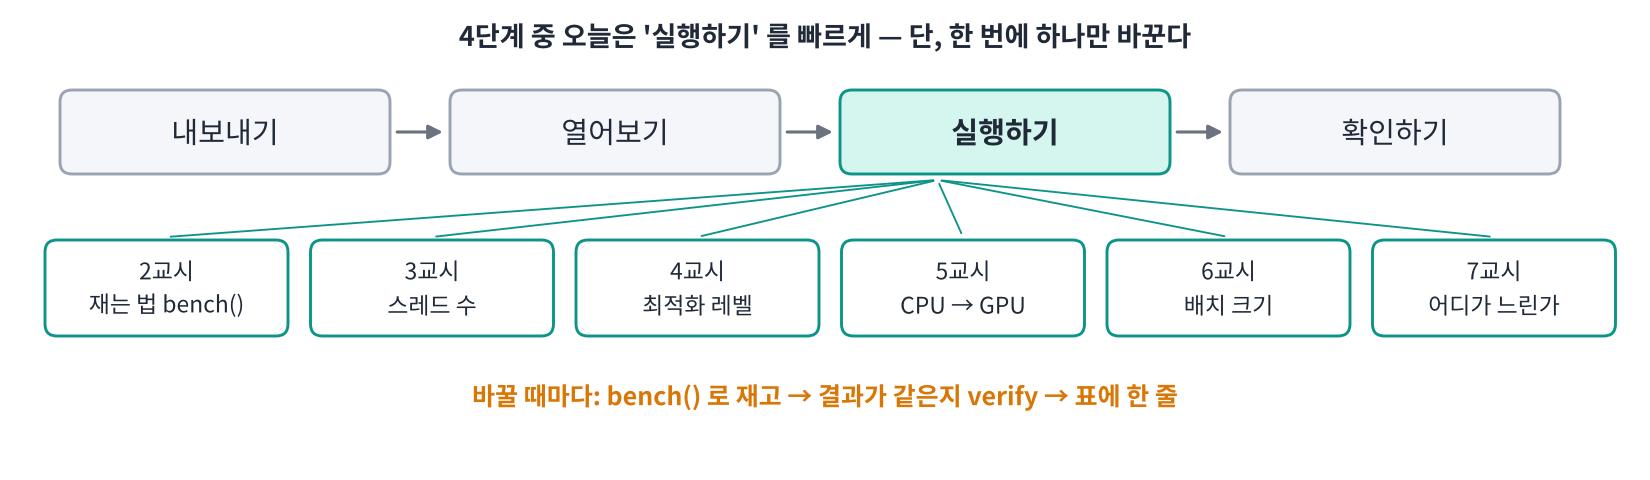

In [ ]:
#@title 🖼 그림 — 오늘의 지도 — 실행하기의 손잡이 다섯 개
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day3/img/f1_map.png", embed=True, width=860))

### 오늘의 실험 원칙

1. **한 번에 하나만 바꾼다.** 스레드와 최적화 레벨을 동시에 바꾸면 무엇 때문에 빨라졌는지 모릅니다.
2. **조건을 함께 적는다.** 모델 · 실행기 · 스레드 · 레벨 · 배치 · 장치 — 표의 열로.
3. **바꾼 뒤에도 결과는 같아야 한다.** 빨라졌는데 답이 달라지면 소용없습니다 (`allclose`).

#### 📌 1교시 정리

- 오늘의 모델: `mnv3s.onnx` (구조만, opset 17, 배치 자유) · `mnist_cnn_dyn.onnx`.
- providers 는 희망 목록 — 실제 실행기는 `sess.get_providers()` 로 확인.

## 2교시 — 시간을 재는 법: warm-up · 평균 · p95 · FPS → `bench()`

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

**시간** 10:00–10:10 그림 '한 번 재면 안 되는 이유' → 10:10–10:35 문제 2-1 ~ 2-3 → 10:35–10:45 🔁 PyTorch vs ORT → 10:45 정리.

**판서**: 시간 100개를 점으로 찍는 시늉 → 가운데 줄 (평균) · 위쪽 줄 (p95). "평균은 '보통', p95 는 '100번 중 5번은 이것보다 늦다'. 실시간 카메라는 늦은 5번에서 프레임을 놓칩니다."

**강조**: 오늘 노트북의 확인 셀은 **숫자 값이 아니라 방법을** 검사한다는 것을 이 교시 시작에 다시 말하세요. 옆 사람과 숫자를 비교하며 불안해하는 학생이 많습니다.

</div>

> 🎬 **애니메이션** [D3-2 재는 법 — warm-up · p95](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/animation.html#d3-2)
> 📝 **워크시트** [2교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/worksheet.html#t2)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

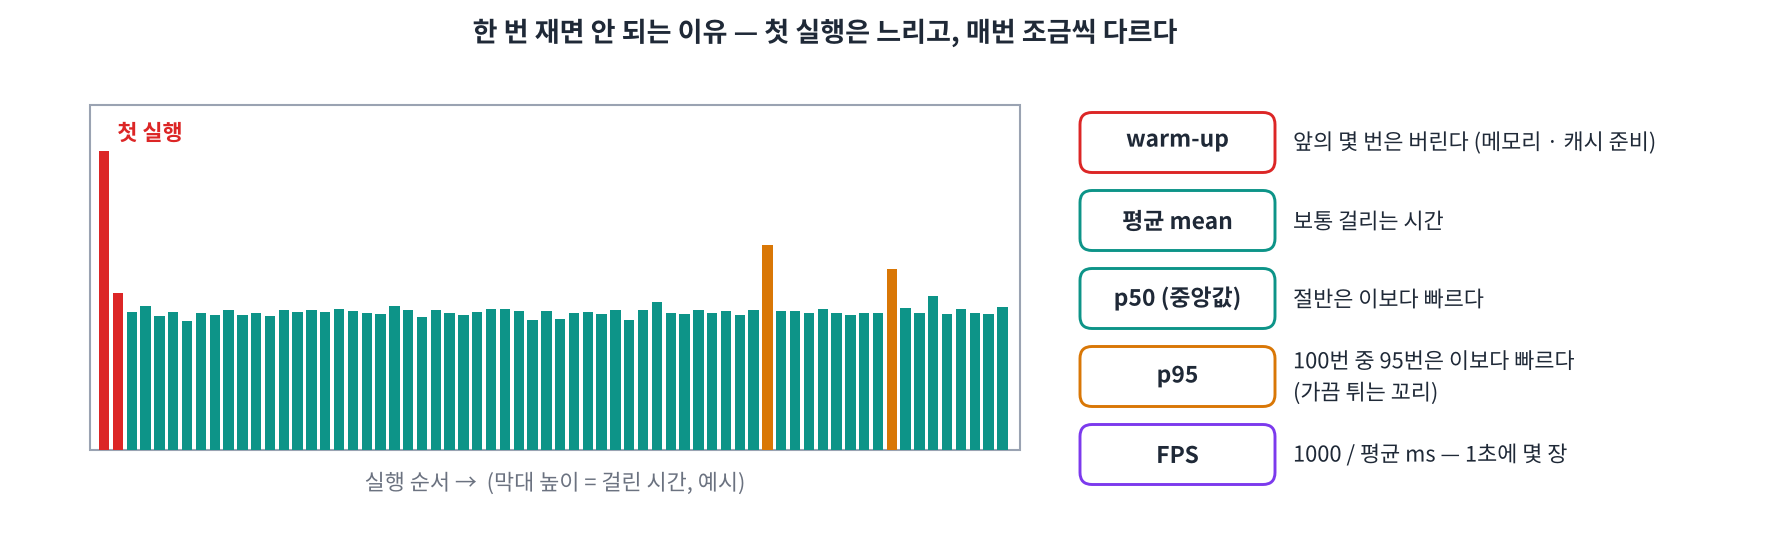

In [ ]:
#@title 🖼 그림 — 한 번 재면 안 되는 이유
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day3/img/f2_timing.png", embed=True, width=860))

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `perf_counter`, `1000` → 실행 예 `[2.2, 2.66, 2.11, 2.5, 2.33]` ms → 0.9배.
- **주의 — 서버 실행 예에서는 첫 실행이 별로 느리지 않았습니다** (0.9배). 1-1 에서 같은 모델 · 같은 입력으로 이미 한 번 돌렸기 때문 (CPU 캐시 · 메모리가 이미 준비됨). Colab 에서는 보통 1.5~3배 차이가 납니다. 차이가 안 나는 학생에게는 "5교시 GPU 첫 실행에서 수백 배 차이를 볼 것" 이라고 예고하세요.

</div>

**문제 2-1** **한 번씩 다섯 번 재기** — `time.perf_counter()` 는 초 단위 시계입니다. 실행 전 · 후 시각의 차이 × 1000 = ms. **새로 만든 세션**으로 5번 연속 재서 첫 실행과 나머지를 비교하세요.

In [ ]:
sess = ort.InferenceSession("mnv3s.onnx", providers=CPU)
first5 = []
for _ in range(5):
    t0 = time.perf_counter()
    sess.run(None, {"input": x1})
    first5.append((time.perf_counter() - t0) * 1000)
print("5번의 시간 (ms):", [round(t, 2) for t in first5])
print(f"첫 실행은 나머지 평균의 {first5[0] / np.mean(first5[1:]):.1f}배")

5번의 시간 (ms): [2.2, 2.66, 2.11, 2.5, 2.33]
첫 실행은 나머지 평균의 0.9배


In [ ]:
assert len(first5) == 5 and all(0 < t < 10_000 for t in first5); print("✅ 같은 일을 했는데 시간이 매번 다르다 — 첫 번째가 가장 느린 경우가 많다 (Colab 에서 더 뚜렷)")

✅ 같은 일을 했는데 시간이 매번 다르다 — 첫 번째가 가장 느린 경우가 많다 (Colab 에서 더 뚜렷)


<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `95`, `1000` → 실행 예: 평균 2.11 ms | p50 2.02 | p95 2.52 | 최대 2.71 | 475 FPS.
- 그래프의 오른쪽 히스토그램에서 '꼬리' 를 손으로 짚어 주세요. 최대값은 한 번의 사고로 흔들려 비교용으로 쓰지 않는다는 점.
- **예상 질문** "p99 는요?" → 100번으로는 p99 = 거의 최대값이라 의미가 약합니다. 더 많이 재야 합니다 (1000번 이상).

</div>

**문제 2-2** **warm-up 10번 버리고 100번 재기** — 100개의 시간 `times` 로 평균 · 중앙값(p50) · **p95** · **FPS** 를 구하세요. p95 는 `np.percentile(times, 95)`, FPS 는 1000 ÷ 평균 ms.

In [ ]:
for _ in range(10):                                   # warm-up — 재지 않고 버린다
    sess.run(None, {"input": x1})
times = []
for _ in range(100):
    t0 = time.perf_counter()
    sess.run(None, {"input": x1})
    times.append((time.perf_counter() - t0) * 1000)
times = np.array(times)
mean, p50, p95 = times.mean(), np.percentile(times, 50), np.percentile(times, 95)
fps = 1000 / mean
print(f"평균 {mean:.2f} ms | p50 {p50:.2f} | p95 {p95:.2f} | 최대 {times.max():.2f} | {fps:.0f} FPS")

평균 2.11 ms | p50 2.02 | p95 2.52 | 최대 2.71 | 475 FPS


In [ ]:
assert len(times) == 100 and abs(p95 - np.percentile(times, 95)) < 1e-9 and abs(fps * mean - 1000) < 1e-6
print("✅ p95 ≥ p50:", p95 >= p50, "— 꼬리가 평균을 얼마나 넘는지 보세요")

✅ p95 ≥ p50: True — 꼬리가 평균을 얼마나 넘는지 보세요


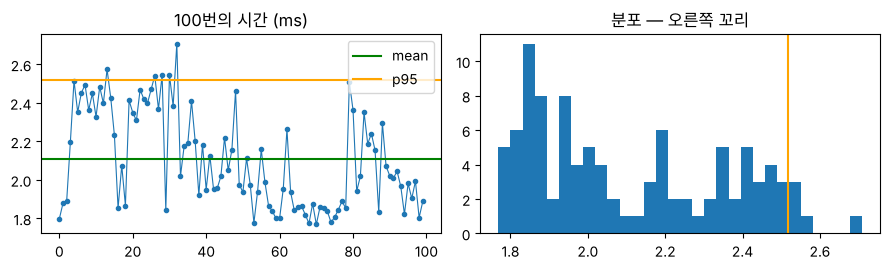

In [ ]:
plt.figure(figsize=(9, 2.8))
plt.subplot(1, 2, 1); plt.plot(times, ".-", lw=0.8); plt.axhline(mean, color="g", label="mean"); plt.axhline(p95, color="orange", label="p95")
plt.title("100번의 시간 (ms)"); plt.legend()
plt.subplot(1, 2, 2); plt.hist(times, bins=30); plt.axvline(p95, color="orange"); plt.title("분포 — 오른쪽 꼬리")
plt.tight_layout(); plt.show()

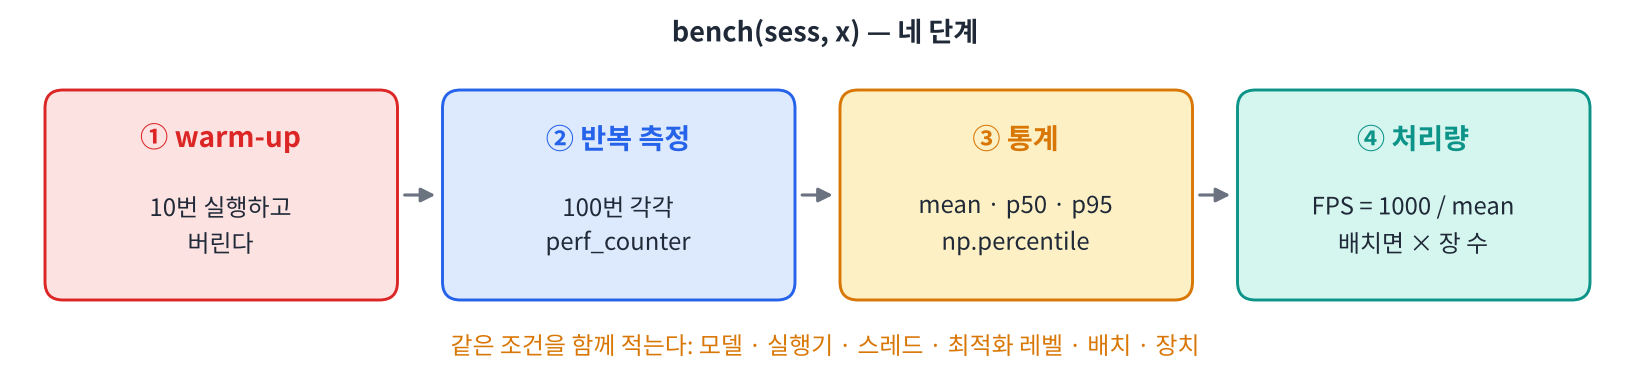

In [ ]:
#@title 🖼 그림 — bench() — 네 단계
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day3/img/f2_bench.png", embed=True, width=860))

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `x.shape[0]` → 실행 예: MobileNetV3 mean 1.90 · fps 526 / SimpleConvNet mean 0.098 · fps 10,252 → 약 19배 (다른 실행에서는 33배 — SimpleConvNet 쪽이 측정 오차에 크게 흔들림).
- `bench` 는 오늘 모든 교시에서 다시 씁니다. **이 셀을 못 끝낸 학생은 정답 셀이라도 실행**하게 하세요 — 이후 전부 NameError 가 납니다.
- SimpleConvNet 은 0.1 ms 대라 측정 오차가 상대적으로 큼 → 오늘 실험은 MobileNetV3 로.

</div>

**문제 2-3** 2-2 를 함수로 묶습니다. `bench(sess, x, n=100, warm=10)` 은 `{"mean", "p50", "p95", "fps"}` 딕셔너리를 돌려줍니다. 입력 이름은 세션에서 읽고, **배치**면 FPS 에 장 수를 곱해 '초당 장 수' 로 만듭니다. 오늘 하루 이 함수 하나로 모든 것을 잽니다.

In [ ]:
def bench(sess, x, n=100, warm=10):
    name = sess.get_inputs()[0].name
    for _ in range(warm):
        sess.run(None, {name: x})
    t = []
    for _ in range(n):
        t0 = time.perf_counter()
        sess.run(None, {name: x})
        t.append((time.perf_counter() - t0) * 1000)
    t = np.array(t)
    return {"mean": t.mean(), "p50": np.percentile(t, 50), "p95": np.percentile(t, 95),
            "fps": 1000 / t.mean() * x.shape[0]}            # 배치 b 장이면 × b

r_mn = bench(sess, x1)
r_cnn = bench(ort.InferenceSession("mnist_cnn_dyn.onnx", providers=CPU), xm)
print("MobileNetV3  ", {k: round(v, 2) for k, v in r_mn.items()})
print("SimpleConvNet", {k: round(v, 3) for k, v in r_cnn.items()})

MobileNetV3   {'mean': np.float64(1.9), 'p50': np.float64(1.84), 'p95': np.float64(2.38), 'fps': np.float64(525.94)}
SimpleConvNet {'mean': np.float64(0.098), 'p50': np.float64(0.09), 'p95': np.float64(0.137), 'fps': np.float64(10252.338)}


In [ ]:
r4 = bench(sess, np.random.rand(4, 3, 224, 224).astype(np.float32), n=10, warm=2)
assert set(r_mn) == {"mean", "p50", "p95", "fps"} and abs(r4["fps"] - 4000 / r4["mean"]) < 1e-6
print(f"✅ bench 완성 — MobileNetV3 가 SimpleConvNet 보다 {r_mn['mean'] / r_cnn['mean']:.0f}배 오래 걸린다")

✅ bench 완성 — MobileNetV3 가 SimpleConvNet 보다 19배 오래 걸린다


<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

실행 예: PyTorch 5.32 ms vs ORT 1.90 ms → 2.8배 (다른 실행 3.4배). VB Day 5 에서 본 'ORT 가 빠르다' 를 오늘의 방법으로 재확인. "왜 빠른가?" → 4교시 답 (그래프 최적화 · 레이아웃) 을 예고만 하고 넘어가세요.

</div>

### 🔁 바꿔보기 — PyTorch 로 돌리면?

같은 모델을 PyTorch 로 재 봅니다 (`torch.no_grad`, CPU). VB Day 5 6교시에서 본 'ORT 가 더 빠르다' 를 오늘의 `bench` 방식으로 다시 확인합니다.

In [ ]:
xt = torch.from_numpy(x1)
with torch.no_grad():
    for _ in range(10):
        mnv3s(xt)
    t = []
    for _ in range(100):
        t0 = time.perf_counter(); mnv3s(xt); t.append((time.perf_counter() - t0) * 1000)
print(f"PyTorch 평균 {np.mean(t):.2f} ms | ONNX Runtime 평균 {r_mn['mean']:.2f} ms → {np.mean(t) / r_mn['mean']:.1f}배")

PyTorch 평균 5.32 ms | ONNX Runtime 평균 1.90 ms → 2.8배


#### ⚠️ 자주 하는 실수

- `time.time()` 으로 한 번만 잼 → 첫 실행이 섞이고 오차가 큽니다.
- 평균만 보고 p95 를 안 봄 → 실시간 시스템에서 가끔 튀는 지연을 놓칩니다.
- 측정 중에 다른 셀을 돌리거나 그래프를 그림 → 같은 CPU 를 나눠 써서 숫자가 흔들립니다. **잴 때는 재기만.**
- 옆 사람과 숫자 비교 → Colab 장비가 사람마다 다를 수 있습니다. **같은 노트북 안에서** 조건만 바꿔 비교하세요.

#### 📌 2교시 정리

- warm-up 10번 버리기 → 100번 재기 → 평균 · p50 · **p95** · FPS.
- `bench(sess, x)` = 오늘의 측정 함수. 배치면 FPS × 장 수 = 초당 장 수.

## 3교시 — 스레드 수: `SessionOptions` · 한 번에 하나만

`InferenceSession` 을 만들 때 **`SessionOptions`** 로 실행 방식을 정할 수 있습니다. 첫 손잡이는 **스레드 수** (`intra_op_num_threads`) — 연산 하나를 몇 명이 나눠서 계산할지입니다.

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

**시간** 11:00–11:10 그림 '일꾼 · 작업대' → 11:10–11:35 문제 3-1 · 3-2 → 11:35–11:45 `make_session` 도구 → 11:45 정리.

**비유 (판서)**: 스레드 = 일꾼, 코어 = 작업대. 작업대 2개에 일꾼 4명 → 서로 비켜 주느라 **가끔** 크게 늦어진다 → 평균보다 p95 가 먼저 나빠진다.

**Colab 코어 수**: 무료 Colab 은 보통 2코어 (`os.cpu_count()` 로 확인). 강사 PC · 실제 장치 (Jetson 6~8코어 등) 에서는 다른 그림이 나온다는 점을 언급.

</div>

> 🎬 **애니메이션** [D3-3 스레드 · 코어](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/animation.html#d3-3)
> 📝 **워크시트** [3교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/worksheet.html#t3)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

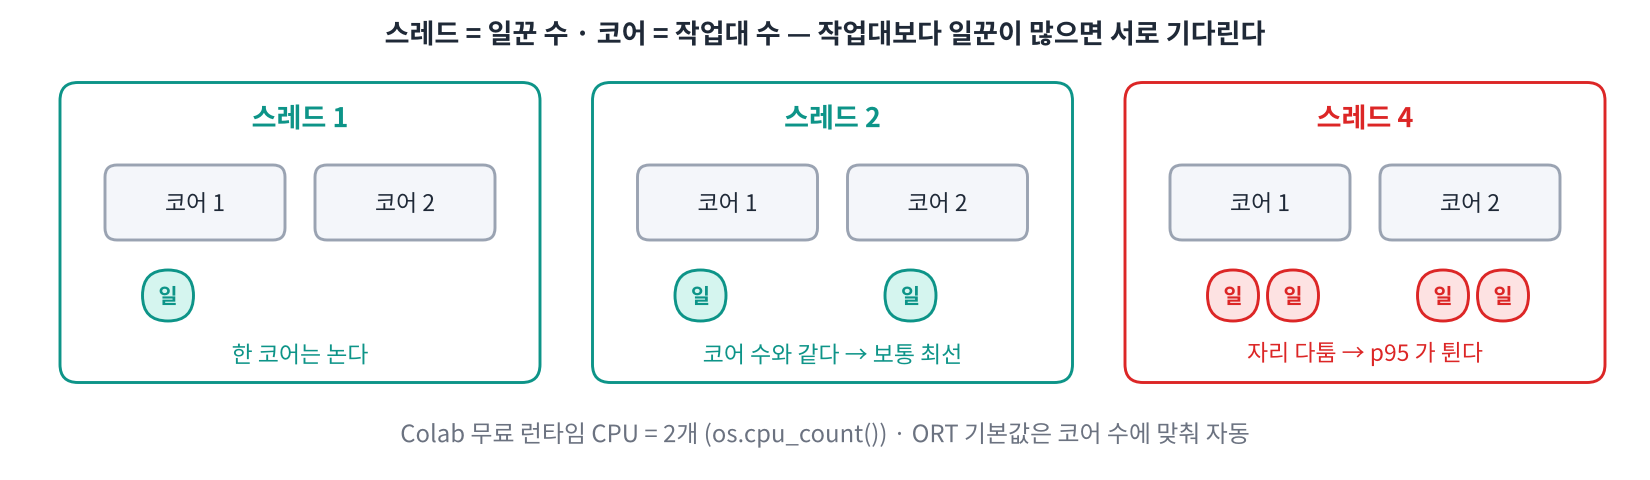

In [ ]:
#@title 🖼 그림 — 스레드 = 일꾼, 코어 = 작업대
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day3/img/f3_threads.png", embed=True, width=860))

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `intra_op_num_threads` → 실행 예 (2코어): 1 → 1.90 ms · p95 2.24 / 2 → 1.79 · 2.21 / **4 → 4.68 · 9.98** (과밀 — p95 가 평균보다 훨씬 크게 나빠짐).
- 옵션 → 세션 순서: 세션을 만든 뒤 `so` 를 바꿔도 반영되지 않는다는 것을 짚어 주세요 (⚠️ 자주 하는 실수 1번).
- `inter_op_num_threads` 를 물으면: 서로 독립된 노드를 동시에 돌릴 때 쓰는 것인데, 기본 실행 모드 (순차) 에서는 영향이 거의 없습니다.

</div>

**문제 3-1** 스레드 1 · 2 · 4 로 세션을 각각 만들어 `bench` 하고, 결과를 표 (`DataFrame`) 로 만드세요. **스레드 말고는 아무것도 바꾸지 않습니다.**

In [ ]:
print("이 런타임의 CPU 코어 수:", os.cpu_count())
rows = []
for th in [1, 2, 4]:
    so = ort.SessionOptions()
    so.intra_op_num_threads = th
    s = ort.InferenceSession("mnv3s.onnx", so, providers=CPU)
    rows.append({"threads": th, **bench(s, x1)})
df_th = pd.DataFrame(rows)
display(df_th)

이 런타임의 CPU 코어 수: 2


,threads,mean,p50,p95,fps
0,1,1.90,1.84,2.24,527.48
1,2,1.79,1.79,2.21,558.05
2,4,4.68,6.05,9.98,213.62


In [ ]:
assert df_th.threads.tolist() == [1, 2, 4] and (df_th[["mean", "p95"]] > 0).all().all()
print("✅ 스레드별 표 — 가장 빠른 평균:", int(df_th.loc[df_th["mean"].idxmin(), "threads"]), "스레드")

✅ 스레드별 표 — 가장 빠른 평균: 2 스레드


<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `idxmin` → 실행 예 2 스레드. 1 스레드와 2 스레드 차이는 작아 실행마다 뒤바뀔 수 있습니다 (다른 실행의 8교시에서는 1 스레드가 최선). **둘 다 정답** — 채점은 '표에서 p95 가 가장 작은 줄을 골랐는가' 만 봅니다.
- 실무 포인트: 장치에서 카메라 수집 · 후처리 같은 다른 일이 같은 CPU 를 쓰면 추론 스레드를 일부러 줄입니다.

</div>

**문제 3-2** **표 읽기** — 코어보다 스레드가 많을 때 평균과 p95 중 무엇이 더 나빠졌나요? 실시간 시스템 기준으로 고를 스레드 수를 **p95 가 가장 작은 줄**에서 꺼내세요.

In [ ]:
best_threads = int(df_th.loc[df_th["p95"].idxmin(), "threads"])
oversub = df_th[df_th.threads > os.cpu_count()]
print("p95 기준 최선:", best_threads, "스레드")
if len(oversub):
    print(f"코어 {os.cpu_count()}개에 스레드 4 → 평균 {oversub['mean'].iloc[0]:.2f} ms · p95 {oversub['p95'].iloc[0]:.2f} ms")

p95 기준 최선: 2 스레드
코어 2개에 스레드 4 → 평균 4.68 ms · p95 9.98 ms


In [ ]:
assert best_threads == int(df_th.sort_values("p95").threads.iloc[0]); print("✅ 실시간이면 p95 로 고른다 —", best_threads, "스레드")

✅ 실시간이면 p95 로 고른다 — 2 스레드


<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

`make_session` 은 학생이 만드는 것이 아니라 **주어진 도구**입니다. 인자 네 개 (threads · level · providers · profile) 가 오늘 손잡이와 1:1 이라는 것만 짚고 실행. 기본값 `threads=0` = 자동, `level="ALL"` = ORT 기본값.

</div>

### 오늘 쓸 세션 만들기 도구 — `make_session`

앞으로는 손잡이를 인자로 받아 세션을 만드는 함수를 씁니다. `level` 은 4교시, `providers` 는 5교시, `profile` 은 7교시에 씁니다.

In [ ]:
LEVELS = {"DISABLE": ort.GraphOptimizationLevel.ORT_DISABLE_ALL, "BASIC": ort.GraphOptimizationLevel.ORT_ENABLE_BASIC,
          "EXTENDED": ort.GraphOptimizationLevel.ORT_ENABLE_EXTENDED, "ALL": ort.GraphOptimizationLevel.ORT_ENABLE_ALL}

def make_session(path, threads=0, level="ALL", providers=None, save_opt=None, profile=False):
    """threads 0 = 자동 · level = DISABLE/BASIC/EXTENDED/ALL · save_opt = 최적화된 그래프 저장 경로"""
    so = ort.SessionOptions()
    so.intra_op_num_threads = threads
    so.graph_optimization_level = LEVELS[level]
    if save_opt:
        so.optimized_model_filepath = save_opt
    if profile:
        so.enable_profiling = True
    return ort.InferenceSession(path, so, providers=providers or CPU)

print({k: round(v, 2) for k, v in bench(make_session("mnv3s.onnx"), x1).items()}, "← 기본 설정 (자동 스레드 · ALL)")

{'mean': np.float64(1.82), 'p50': np.float64(1.83), 'p95': np.float64(1.9), 'fps': np.float64(547.96)} ← 기본 설정 (자동 스레드 · ALL)


#### ⚠️ 자주 하는 실수

- `so.intra_op_num_threads` 를 세션을 **만든 뒤**에 바꿈 → 이미 만든 세션에는 적용되지 않습니다. 옵션 → 세션 순서.
- 스레드와 다른 것을 같이 바꿈 → 무엇 때문에 달라졌는지 알 수 없습니다.
- 스레드를 늘리면 무조건 빨라진다고 생각 → 코어 수가 상한. 작은 연산은 나누는 비용이 더 클 수도 있습니다.

#### 📌 3교시 정리

- `SessionOptions` → `intra_op_num_threads` → `InferenceSession(path, so, providers)`.
- 코어 수 = 보통 최선. 넘으면 **p95 부터** 나빠진다. 기본값 0 = 자동.

## 4교시 — 그래프 최적화 레벨: 노드 합치기 · 레이아웃

ONNX Runtime 은 세션을 만들 때 그래프를 **스스로 고칩니다**. 어제 onnxslim 이 한 일 (상수 접기) 보다 더 나아가, 노드를 합치고 데이터 배치까지 바꿉니다. 얼마나 고칠지가 `graph_optimization_level` 입니다.

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

**시간** 13:00–13:10 그림 '레벨 4단계' → 13:10–13:30 문제 4-1 · 노드 합치기 그림 → 13:30–13:45 문제 4-2 · 🔁 allclose → 13:45 정리.

**연결 (판서)**: 어제 onnxslim = '파일을 고쳐 저장'. 오늘 ORT 최적화 = '세션을 만들 때 메모리 안에서 고침' (파일은 그대로). `save_opt` 는 그 고친 결과를 구경하려고 꺼내 보는 것.

**어제 떡밥 회수**: Day 2 5-3 오류 메시지에 `FusedGemm` 이 나왔던 것을 기억하는 학생이 있으면 4-1 에서 바로 연결하세요.

</div>

> 🎬 **애니메이션** [D3-4 최적화 레벨 · 노드 합치기](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/animation.html#d3-4)
> 📝 **워크시트** [4교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/worksheet.html#t4)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

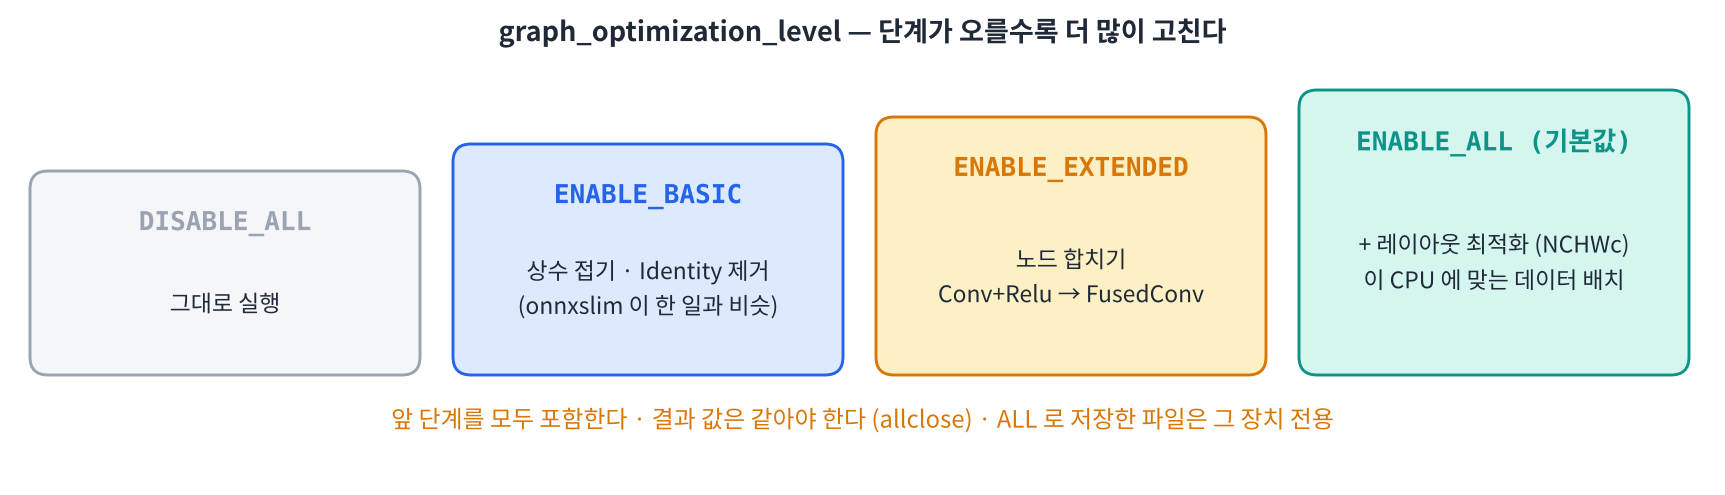

In [ ]:
#@title 🖼 그림 — 최적화 레벨 4단계
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day3/img/f4_levels.png", embed=True, width=880))

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `lv` → 실행 예 (같아야 함): DISABLE 7 · BASIC 7 · EXTENDED 5 `[FusedConv, MaxPool, Flatten, FusedGemm, Gemm]` · ALL 6 `[Conv, ReorderOutput, MaxPool, Flatten, FusedGemm, Gemm]`.
- ALL 에서 `Conv` 가 다시 보이는 것은 **NCHWc 전용 Conv** (domain `com.microsoft.nchwc`) 입니다. 이름은 같아도 다른 연산.
- 노란 경고 `Serializing optimized model ... hardware specific` 은 정상 — 바로 이 교시의 ⚠️ 1번 내용이니 읽어 주세요.
- **예상 질문** "그럼 FusedConv 파일을 배포하면 더 빠르지 않나요?" → 장치의 ORT 가 어차피 세션을 만들 때 같은 최적화를 합니다. 원본을 배포하는 것이 안전 (다른 실행기 · TensorRT 는 com.microsoft 연산을 모름).

</div>

**문제 4-1** SimpleConvNet 을 네 레벨로 열면서 **ORT 가 고친 그래프를 파일로 저장**하게 하고 (`save_opt`), 레벨별 노드 목록을 비교하세요.

In [ ]:
ops_by_level = {}
for lv in ["DISABLE", "BASIC", "EXTENDED", "ALL"]:
    make_session("mnist_cnn_dyn.onnx", level=lv, save_opt=f"cnn_opt_{lv}.onnx")
    g_ = onnx.load(f"cnn_opt_{lv}.onnx").graph
    ops_by_level[lv] = [n.op_type for n in g_.node]
    print(lv.ljust(9), len(ops_by_level[lv]), "개:", ops_by_level[lv])

DISABLE   7 개: ['Conv', 'Relu', 'MaxPool', 'Flatten', 'Gemm', 'Relu', 'Gemm']
BASIC     7 개: ['Conv', 'Relu', 'MaxPool', 'Flatten', 'Gemm', 'Relu', 'Gemm']
EXTENDED  5 개: ['FusedConv', 'MaxPool', 'Flatten', 'FusedGemm', 'Gemm']
ALL       6 개: ['Conv', 'ReorderOutput', 'MaxPool', 'Flatten', 'FusedGemm', 'Gemm']


2026-11-06 10:44:16.630664089 [W:onnxruntime:, inference_session.cc:2813 Initialize] Serializing optimized model with Graph Optimization level greater than ORT_ENABLE_EXTENDED and the NchwcTransformer enabled. The generated model may contain hardware specific optimizations, and should only be used in the same environment the model was optimized in.


In [ ]:
assert len(ops_by_level["DISABLE"]) == 7 and "FusedConv" in ops_by_level["EXTENDED"] and "FusedGemm" in ops_by_level["EXTENDED"]
print("✅ EXTENDED 에서 Conv+Relu → FusedConv, Gemm+Relu → FusedGemm")

✅ EXTENDED 에서 Conv+Relu → FusedConv, Gemm+Relu → FusedGemm


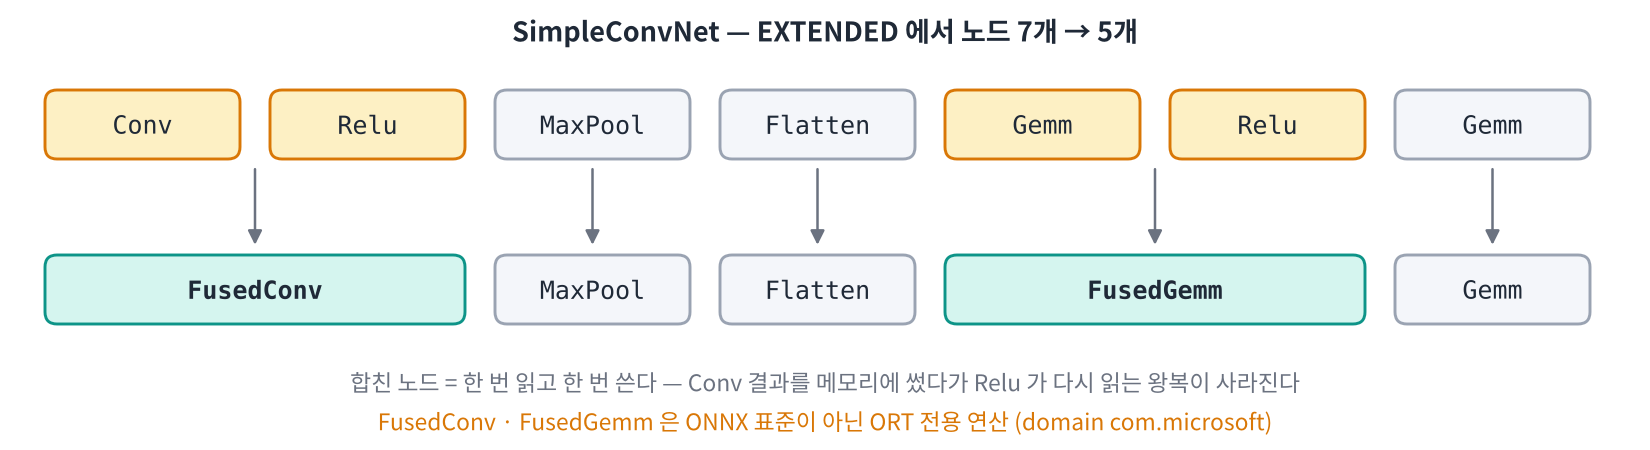

In [ ]:
#@title 🖼 그림 — SimpleConvNet — 노드 합치기
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day3/img/f4_fusion.png", embed=True, width=860))

In [ ]:
display(describe_onnx("cnn_opt_EXTENDED.onnx"))       # domain 열: com.microsoft = ORT 전용 연산

,op_type,domain,params
0,FusedConv,com.microsoft,780
1,MaxPool,,0
2,Flatten,,0
3,FusedGemm,com.microsoft,432100
4,Gemm,,1010


<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `mean` → 실행 예: DISABLE 5.25 · BASIC 5.29 · EXTENDED 5.44 · **ALL 1.86 ms (2.8배)**. 다른 실행에서는 2.5배 — 2.5~3배 범위.
- 왜 EXTENDED 까지는 거의 그대로인가: MobileNetV3 의 시간 대부분이 Conv 계산 자체라 노드를 몇 개 합쳐도 줄어드는 몫이 작음. ALL 의 레이아웃 (NCHWc) 이 Conv 계산을 CPU 의 SIMD 에 맞춰 크게 빠르게 함.
- 참고: DISABLE 에서 노드가 146 개로 오히려 늘어나는데, ORT 가 HardSwish 를 HardSigmoid + Mul 로 풀어 실행하기 때문 (물으면만).

</div>

**문제 4-2** 이제 MobileNetV3 로 **레벨만** 바꿔 시간을 잽니다 (스레드는 자동). 표를 만들고 DISABLE 대비 몇 배 빨라졌는지 `speedup` 열을 추가하세요.

In [ ]:
rows = []
for lv in ["DISABLE", "BASIC", "EXTENDED", "ALL"]:
    rows.append({"level": lv, **bench(make_session("mnv3s.onnx", level=lv), x1)})
df_lv = pd.DataFrame(rows)
df_lv["speedup"] = df_lv["mean"].iloc[0] / df_lv["mean"]
display(df_lv)

,level,mean,p50,p95,fps,speedup
0,DISABLE,5.25,5.24,5.45,190.35,1.00
1,BASIC,5.29,5.26,5.49,188.96,0.99
2,EXTENDED,5.44,5.24,6.19,183.86,0.97
3,ALL,1.86,1.81,2.21,537.94,2.83


In [ ]:
assert df_lv.level.tolist() == ["DISABLE", "BASIC", "EXTENDED", "ALL"] and abs(df_lv.speedup.iloc[0] - 1) < 1e-9
print(f"✅ ALL 은 DISABLE 보다 {df_lv.speedup.iloc[3]:.1f}배")

✅ ALL 은 DISABLE 보다 2.8배


<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

실행 예: BASIC · EXTENDED 최대 차이 0, ALL 1e-9 수준 → 모두 allclose True. '최적화는 계산 순서만 바꾸고 계산 내용은 바꾸지 않는다' (FP32 범위 내 반올림 차이만). Day 4 FP16 에서는 이 차이가 커진다는 예고.

</div>

### 🔁 바꿔보기 — 빨라져도 답은 같은가?

실험 원칙 3. 네 레벨의 출력을 DISABLE 과 비교합니다.

In [ ]:
base = make_session("mnv3s.onnx", level="DISABLE").run(None, {"input": x1})[0]
for lv in ["BASIC", "EXTENDED", "ALL"]:
    out = make_session("mnv3s.onnx", level=lv).run(None, {"input": x1})[0]
    print(lv.ljust(9), "최대 차이", f"{np.abs(out - base).max():.1e}", "| allclose:", np.allclose(out, base, atol=1e-4))

BASIC     최대 차이 0.0e+00 | allclose: True
EXTENDED  최대 차이 0.0e+00 | allclose: True
ALL       최대 차이 2.6e-09 | allclose: True


#### ⚠️ 자주 하는 실수

- `optimized_model_filepath` 로 저장한 **ALL** 그래프를 다른 컴퓨터에 배포 → 그 장치 전용이라 다른 CPU 에서 문제가 될 수 있습니다 (ORT 도 경고를 냅니다).
- 최적화 레벨을 낮추면 '원래 모델 그대로라 더 정확' 하다고 생각 → 결과는 같습니다 (위 비교). 속도만 다릅니다.
- `FusedConv` 가 들어간 파일을 TensorRT · 다른 실행기에 넣음 → ORT 전용 연산이라 읽지 못합니다.

#### 📌 4교시 정리

- DISABLE → BASIC (상수 접기) → EXTENDED (노드 합치기: FusedConv · FusedGemm) → ALL (레이아웃, **기본값**).
- 합치기 = 메모리 왕복 감소. 레이아웃 = CPU 명령에 맞는 데이터 배치. 결과는 같다.

## 5교시 — CPU → GPU: `CUDAExecutionProvider`

손잡이 세 번째는 **어디서 계산할지**. providers 맨 앞에 `CUDAExecutionProvider` 를 두면 GPU 에서 실행합니다. 코드 한 단어지만, **CPU ↔ GPU 사이에 데이터를 나르는 시간**이 새로 생깁니다.

> 1-2 에서 `GPU_OK` 가 False 였다면 이 교시의 셀은 '건너뜀' 을 출력합니다. 런타임 유형을 T4 GPU 로 바꾸고 **설치 셀부터** 다시 실행하거나, 강사 화면으로 결과를 봅니다.

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

**시간** 14:00–14:10 그림 '복사 · 계산 · 복사' → 14:10–14:40 문제 5-1 ~ 5-3 → 14:40 정리.

**⚠️ 이 교시의 출력은 서버에 GPU 가 없어 `GPU 없음 — 건너뜀` 으로 찍혀 있습니다.** 수업 전 Colab T4 에서 직접 돌린 숫자를 메모해 두고 '실행 예' 로 쓰세요. 일반적으로 T4 · MobileNetV3-Small 에서 기대되는 경향:
- 첫 실행: 수백 ms ~ 수 초 (cuDNN 알고리즘 탐색 · CUDA 초기화). 이후 수 ms 이하.
- 배치 1: GPU 와 CPU 의 차이가 작거나 CPU 가 이김 (복사 · 실행 준비 비중이 큼).
- 배치 32: GPU 처리량이 CPU (실행 예 406 장/초) 보다 크게 높음.
- GPU vs CPU 최대 차이: 1e-6 ~ 1e-5 수준.

**GPU 를 못 받은 학생**: 강사 화면을 같이 보게 하고, 확인 셀은 그대로 ✅ 가 나오니 진도는 함께 갑니다.

</div>

> 🎬 **애니메이션** [D3-5 CPU → GPU](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/animation.html#d3-5)
> 📝 **워크시트** [5교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/worksheet.html#t5)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

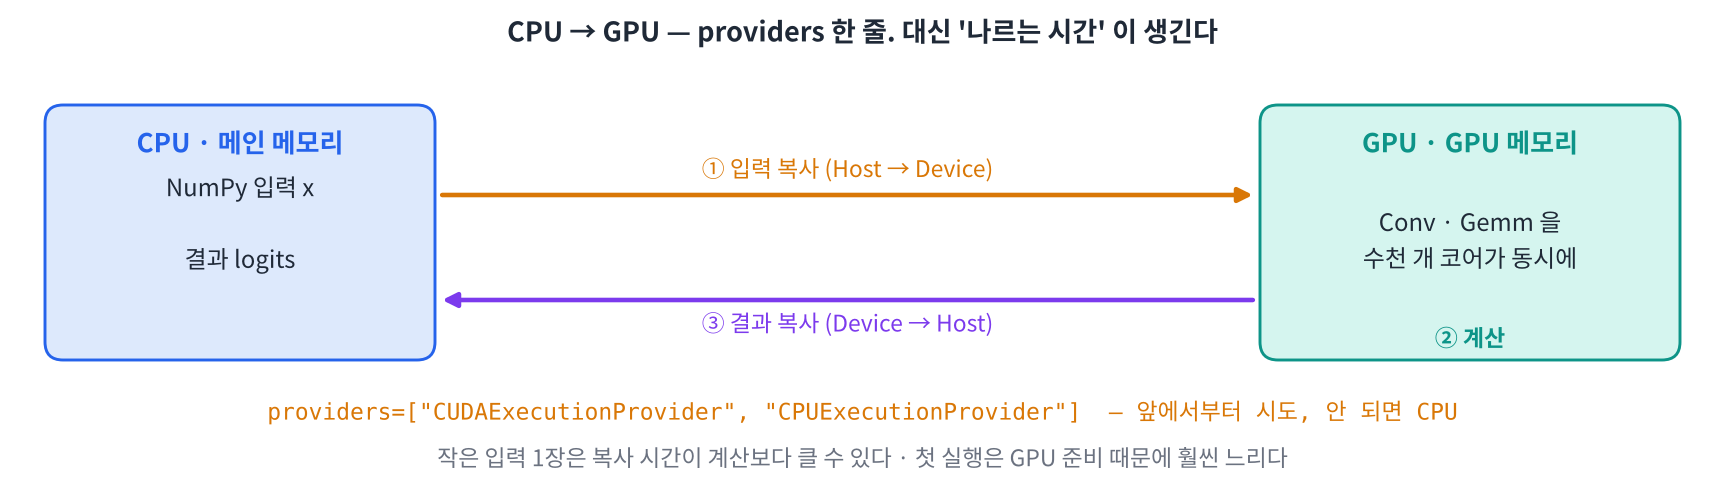

In [ ]:
#@title 🖼 그림 — GPU 실행 — 복사 · 계산 · 복사
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day3/img/f5_gpu.png", embed=True, width=880))

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `"CUDAExecutionProvider"`. Colab 출력의 첫 번째 시간 (보통 수백 ms 이상) 과 다섯 번째를 판서로 비교 — "CPU 의 2-1 보다 첫 실행 문제가 훨씬 크다 → 서비스는 시작할 때 미리 한 번 돌려 둔다".
- `실제 실행기` 가 CPU 로 나오면 1-2 문제 (설치 · 런타임) 로 돌아가세요.

</div>

**문제 5-1** GPU 세션을 만들고 **첫 실행 5번**을 재 보세요 (2-1 과 같은 방법). GPU 는 처음에 준비할 것이 훨씬 많습니다.

In [ ]:
if GPU_OK:
    gpu_sess = make_session("mnv3s.onnx", providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
    print("실제 실행기:", gpu_sess.get_providers()[0])
    g5 = []
    for _ in range(5):
        t0 = time.perf_counter(); gpu_sess.run(None, {"input": x1}); g5.append((time.perf_counter() - t0) * 1000)
    print("GPU 첫 5번 (ms):", [round(t, 2) for t in g5])
else:
    gpu_sess, g5 = None, []
    print("GPU 없음 — 건너뜀")

GPU 없음 — 건너뜀


In [ ]:
assert (not GPU_OK) or (gpu_sess.get_providers()[0] == "CUDAExecutionProvider" and len(g5) == 5)
print("✅", f"GPU 첫 실행 {g5[0]:.0f} ms vs 다섯 번째 {g5[-1]:.2f} ms" if GPU_OK else "GPU 없음 — 설명으로 진행")

✅ GPU 없음 — 설명으로 진행


<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `x_.shape[0]` → 서버 실행 예 (CPU 두 줄만): 배치 1 2.02 ms · 496 장/초 / 배치 32 78.75 ms · 406 장/초.
- GPU 두 줄이 붙으면 **fps 열 (= 초당 장 수)** 을 기준으로 비교하게 하세요. 배치 1 에서 GPU 가 졌다고 실망하는 학생에게 → 6교시 '처리량' 과 Day 4 TensorRT 로 연결.
- 배치 32 는 `n=30` — GPU 메모리 부족 오류가 나면 16 으로.

</div>

**문제 5-2** CPU (기본 설정) 와 GPU 를 **배치 1** 과 **배치 32** 로 각각 `bench` 해 표로 비교하세요. 배치 1 에서는 누가 이기고, 배치 32 에서는 누가 이기나요?

In [ ]:
x32 = np.random.rand(32, 3, 224, 224).astype(np.float32)
cpu_sess = make_session("mnv3s.onnx")
rows = []
for dev, s_ in [("CPU", cpu_sess), ("GPU", gpu_sess)]:
    if s_ is None:
        continue
    for x_ in [x1, x32]:
        rows.append({"device": dev, "batch": x_.shape[0], **bench(s_, x_, n=30, warm=5)})
df_dev = pd.DataFrame(rows)
display(df_dev)

,device,batch,mean,p50,p95,fps
0,CPU,1,2.02,2.01,2.20,495.59
1,CPU,32,78.75,81.28,103.07,406.35


In [ ]:
assert len(df_dev) == (4 if GPU_OK else 2) and set(df_dev.batch) == {1, 32}
if GPU_OK:
    f = df_dev.set_index(["device", "batch"])["fps"]
    print(f"✅ 배치 1: GPU/CPU = {f['GPU', 1] / f['CPU', 1]:.1f}배 · 배치 32: GPU/CPU = {f['GPU', 32] / f['CPU', 32]:.1f}배")
else:
    print("✅ CPU 두 줄 — GPU 줄은 강사 화면으로")

✅ CPU 두 줄 — GPU 줄은 강사 화면으로


<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `max` → GPU 없으면 0.0 으로 통과. Colab 실행 예는 보통 1e-6 ~ 1e-5, 예측 일치율 1.00.
- 기준을 `atol=1e-3` 으로 느슨하게 잡은 이유: GPU (cuDNN) 는 다른 알고리즘 · 덧셈 순서를 쓰므로. Day 4 FP16 에서는 1e-2 대까지 커질 수 있어 기준을 다시 정합니다.

</div>

**문제 5-3** GPU 결과가 CPU 결과와 **같은지** 확인하세요 (실험 원칙 3). GPU 는 다른 계산 방법 (cuDNN 커널) 을 쓰므로 CPU 끼리보다 차이가 조금 큽니다 — `atol=1e-3` 으로 판정합니다.

In [ ]:
out_cpu = cpu_sess.run(None, {"input": x32})[0]
if GPU_OK:
    out_gpu = gpu_sess.run(None, {"input": x32})[0]
    gpu_diff = float(np.abs(out_gpu - out_cpu).max())
    print(f"GPU vs CPU 최대 차이 {gpu_diff:.1e} | 예측 일치율 {(out_gpu.argmax(1) == out_cpu.argmax(1)).mean():.2f}")
else:
    gpu_diff = 0.0
    print("GPU 없음 — 건너뜀")

GPU 없음 — 건너뜀


In [ ]:
assert gpu_diff < 1e-3; print("✅ 장치가 달라도 같은 모델")

✅ 장치가 달라도 같은 모델


#### ⚠️ 자주 하는 실수

- `onnxruntime` 과 `onnxruntime-gpu` 를 둘 다 설치 → 어느 쪽이 import 되는지 꼬여 GPU 가 안 보입니다. 설치 셀처럼 CPU 판을 지우고 GPU 판만.
- providers 에 CUDA 를 넣었으니 GPU 일 거라 믿음 → **`get_providers()` 로 확인.** 라이브러리가 안 맞으면 조용히 CPU 로 돌아갑니다.
- GPU warm-up 없이 첫 실행 시간을 성능으로 기록 → 수백 배 느리게 보입니다.
- 배치 1 하나만 재고 'GPU 가 별로' 라고 결론 → GPU 는 일이 많을수록 유리합니다 (6교시).

#### 📌 5교시 정리

- `providers=["CUDAExecutionProvider", "CPUExecutionProvider"]` → `get_providers()` 로 실제 확인.
- GPU = 계산은 빠르지만 **복사 · 첫 실행 준비** 비용. 작은 일에는 이득이 작고, 배치가 크면 크게 유리.
- 장치가 바뀌어도 결과는 같아야 한다 (`atol=1e-3`).

## 6교시 — 배치 크기: 지연 vs 처리량

5교시에서 배치를 바꾸니 GPU 의 결과가 크게 달라졌습니다. 이번엔 CPU 에서 배치를 1 → 64 로 늘리며 두 가지 숫자를 따로 봅니다.

| 숫자 | 뜻 | 중요한 상황 |
|---|---|---|
| **지연** (latency, ms) | 한 번 `run` 이 끝날 때까지 걸린 시간 | 실시간 카메라 — 프레임마다 바로 답 |
| **처리량** (throughput, 장/초) | 1초에 처리하는 사진 수 = 배치 × 1000 ÷ 지연 | 녹화 영상 일괄 처리 · 여러 카메라 |

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

**시간** 15:00–15:10 그림 '지연과 처리량' + 표 → 15:10–15:40 문제 6-1 ~ 6-3 → 15:40 정리.

**비유 (판서)**: 엘리베이터 — 한 명씩 태우면 각자 빨리 도착 (지연 ↓) 하지만 1시간에 나르는 사람 수 (처리량) 는 적다. 꽉 채우면 처리량 ↑, 대신 마지막 사람은 기다린다.

**현장 연결**: 11/25~ 현장 안전 프로젝트 — '장치 한 대에 카메라 몇 대' 를 정하는 계산이 6-3. 8교시 과제도 이 질문입니다.

</div>

> 🎬 **애니메이션** [D3-6 지연 vs 처리량](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/animation.html#d3-6)
> 📝 **워크시트** [6교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/worksheet.html#t6)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

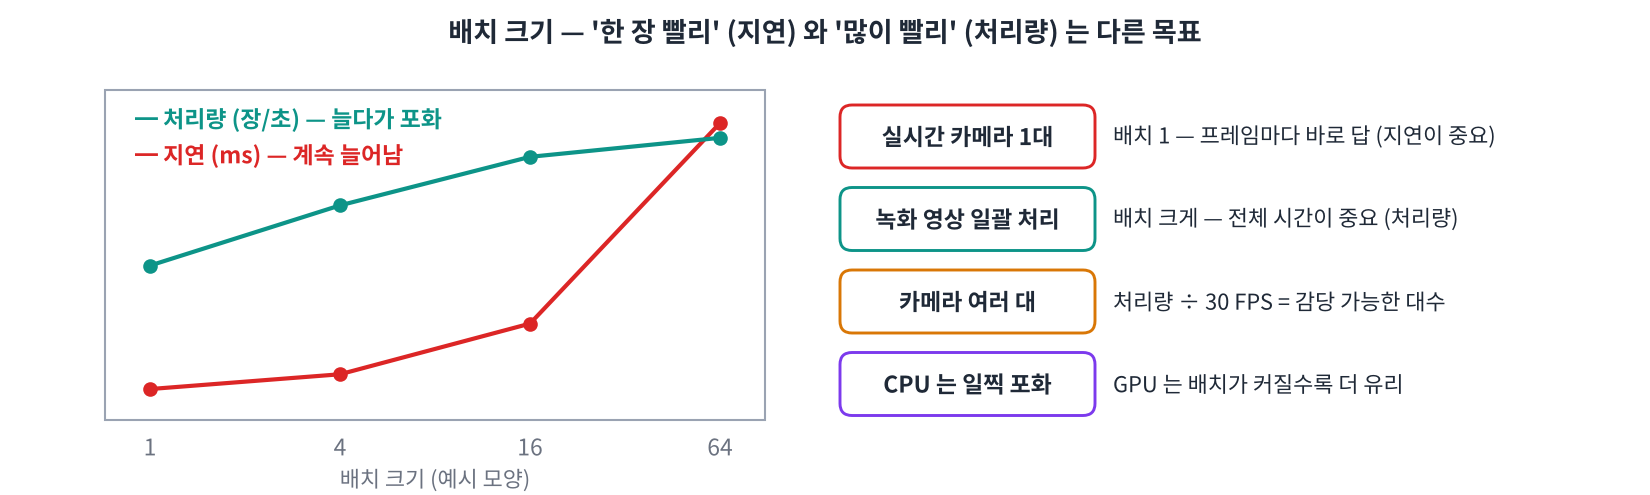

In [ ]:
#@title 🖼 그림 — 배치 크기 — 지연과 처리량
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day3/img/f6_batch.png", embed=True, width=860))

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `"mean"`, `b` → 실행 예 (CPU 2코어): 배치 1 1.90 ms · 527 / **4 7.49 ms · 534** / 16 39.07 · 409 / 64 125.72 · 509 장/초.
- 이 실행은 16 이 64 보다 낮게 나온 '흔들린' 예입니다 (측정 중 서버가 다른 작업을 함) — 반복 수가 20번이라 큰 배치는 흔들리기 쉽습니다. 다른 실행 예: 520 · **590** · 507 · 464 (최대 후 감소). 공통점: CPU 는 배치를 키워도 처리량이 2코어 한계에서 금방 멈춘다.
- 학생 화면이 이렇게 흔들리면 '측정 오차도 실험 결과의 일부 — n 을 늘려 다시 재 본다' 로 활용하세요. GPU 라면 64 까지 계속 오르는 그림 — 5교시 GPU 숫자와 대비.

</div>

**문제 6-1** CPU 기본 설정으로 배치 1 · 4 · 16 · 64 를 재서 표를 만드세요. `bench` 의 `fps` 가 이미 처리량 (장/초) 입니다. 열 이름을 `latency_ms` · `imgs_per_s` 로 정리합니다.

In [ ]:
rows = []
for b in [1, 4, 16, 64]:
    xb = np.random.rand(b, 3, 224, 224).astype(np.float32)
    r = bench(cpu_sess, xb, n=20, warm=3)
    rows.append({"batch": b, "latency_ms": r["mean"], "imgs_per_s": r["fps"], "ms_per_img": r["mean"] / b})
df_b = pd.DataFrame(rows)
display(df_b)

,batch,latency_ms,imgs_per_s,ms_per_img
0,1,1.90,527.00,1.90
1,4,7.49,534.40,1.87
2,16,39.07,409.48,2.44
3,64,125.72,509.07,1.96


In [ ]:
assert df_b.batch.tolist() == [1, 4, 16, 64] and np.allclose(df_b.ms_per_img * df_b.imgs_per_s, 1000)
print("✅ 지연은 배치와 함께 늘고, 장당 시간 · 처리량은 어느 지점에서 멈춘다")

✅ 지연은 배치와 함께 늘고, 장당 시간 · 처리량은 어느 지점에서 멈춘다


<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `idxmax` → 실행 예 배치 4 (534 장/초). Colab 에서는 1 이나 16 이 나올 수도 — 채점은 '표에서 최대를 골랐는가'.
- 그래프의 두 축 (빨강 지연 · 초록 처리량) 을 손으로 따라가며 '두 곡선이 다른 방향' 을 강조.

</div>

**문제 6-2** 두 숫자를 그래프로 그리고, **처리량이 가장 큰 배치** `best_batch` 를 고르세요.

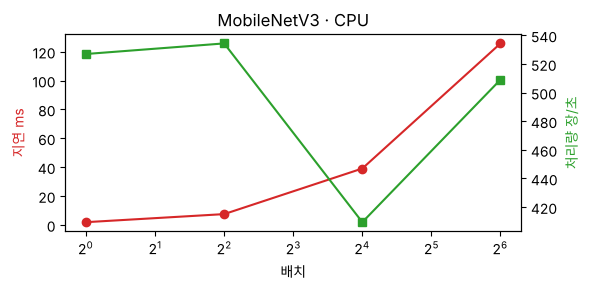

처리량 최대 배치: 4 → 534 장/초


In [ ]:
fig, ax1 = plt.subplots(figsize=(6, 3))
ax1.plot(df_b.batch, df_b.latency_ms, "o-", color="tab:red"); ax1.set_ylabel("지연 ms", color="tab:red"); ax1.set_xscale("log", base=2)
ax2 = ax1.twinx(); ax2.plot(df_b.batch, df_b.imgs_per_s, "s-", color="tab:green"); ax2.set_ylabel("처리량 장/초", color="tab:green")
ax1.set_xlabel("배치"); plt.title("MobileNetV3 · CPU"); plt.tight_layout(); plt.show()
best_batch = int(df_b.loc[df_b.imgs_per_s.idxmax(), "batch"])
print("처리량 최대 배치:", best_batch, f"→ {df_b.imgs_per_s.max():.0f} 장/초")

In [ ]:
assert best_batch == int(df_b.sort_values("imgs_per_s").batch.iloc[-1]); print("✅", best_batch)

✅ 4


<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `30` → 실행 예 배치 1: 17대 · 배치 4: 17대 (지연 7 ms) — 처리량이 거의 같으면 모아서 처리할 이유가 없다는 좋은 예. 다른 실행: 17대 · 19대.
- **함정 질문**: "그럼 17대 붙이면 되나요?" → 이 숫자는 '추론만' 입니다. 실제로는 카메라 디코딩 · 전처리 · 후처리 · 통신이 같은 CPU 를 씁니다. 여유 (보통 50% 이상) 를 두고 정한다는 것을 꼭 말하세요.

</div>

**문제 6-3** **카메라 몇 대?** 카메라 한 대가 **30 FPS** 로 사진을 보낸다면, 이 CPU 하나로 감당할 수 있는 카메라 수는? ① 배치 1 (프레임마다 바로 처리) 과 ② 처리량 최대 배치 (여러 카메라 프레임을 모아서 처리) 두 경우를 정수로 구하세요.

In [ ]:
cams_b1 = int(df_b.imgs_per_s.iloc[0] // 30)
cams_best = int(df_b.imgs_per_s.max() // 30)
print(f"배치 1: {cams_b1}대 | 배치 {best_batch}: {cams_best}대 (지연 {df_b.latency_ms.max() if best_batch == 64 else df_b.set_index('batch').latency_ms[best_batch]:.0f} ms)")

배치 1: 17대 | 배치 4: 17대 (지연 7 ms)


In [ ]:
assert cams_b1 == int(df_b.imgs_per_s.iloc[0] // 30) and cams_best >= cams_b1; print("✅ 처리량 ÷ 30 = 감당 가능한 카메라 수")

✅ 처리량 ÷ 30 = 감당 가능한 카메라 수


#### ⚠️ 자주 하는 실수

- 배치 b 의 시간을 그대로 '한 장 시간' 으로 씀 → 장당 시간 = 지연 ÷ b.
- 처리량만 보고 배치를 크게 → 실시간에서는 지연이 예산 (30 FPS 면 33 ms) 을 넘으면 안 됩니다.
- 큰 배치를 GPU 메모리 생각 없이 → GPU 는 메모리가 넘치면 오류 (`Failed to allocate memory`).

#### 📌 6교시 정리

- 지연 = 한 번 run 시간, 처리량 = 배치 × 1000 ÷ 지연.
- 실시간 → 배치 1 · p95. 일괄 처리 · 여러 카메라 → 처리량 큰 배치.
- 카메라 수 = 처리량 ÷ 카메라 FPS.

## 7교시 — profiling: 어디가 느린가

지금까지는 '전체' 시간을 쟀습니다. 더 빠르게 하려면 **어느 노드가 시간을 먹는지** 알아야 합니다. ORT 의 profiling 을 켜면 노드마다 걸린 시간을 JSON 파일로 남깁니다.

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

**시간** 16:00–16:10 그림 'profiling 다섯 단계' → 16:10–16:40 문제 7-1 ~ 7-3 → 16:40 정리.

**메시지**: 지금까지 '전체 시간' 을 쟀다면, 이제 '어느 노드가' — 더 빠르게 만들려면 오래 걸리는 곳을 고쳐야 한다. 1위가 Conv 이면 Day 4 (TensorRT) · 11/16 (Quantization) 이 바로 Conv 를 빠르게 하는 수업.

**시연 (여유가 있으면)**: 7-1 에서 만들어진 JSON 을 다운로드해 [ui.perfetto.dev](https://ui.perfetto.dev) 에 끌어다 놓으면 노드별 막대 타임라인이 보입니다. 학생 반응이 좋습니다 (2분).

</div>

> 🎬 **애니메이션** [D3-7 profiling — 병목 찾기](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/animation.html#d3-7)
> 📝 **워크시트** [7교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/worksheet.html#t7)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

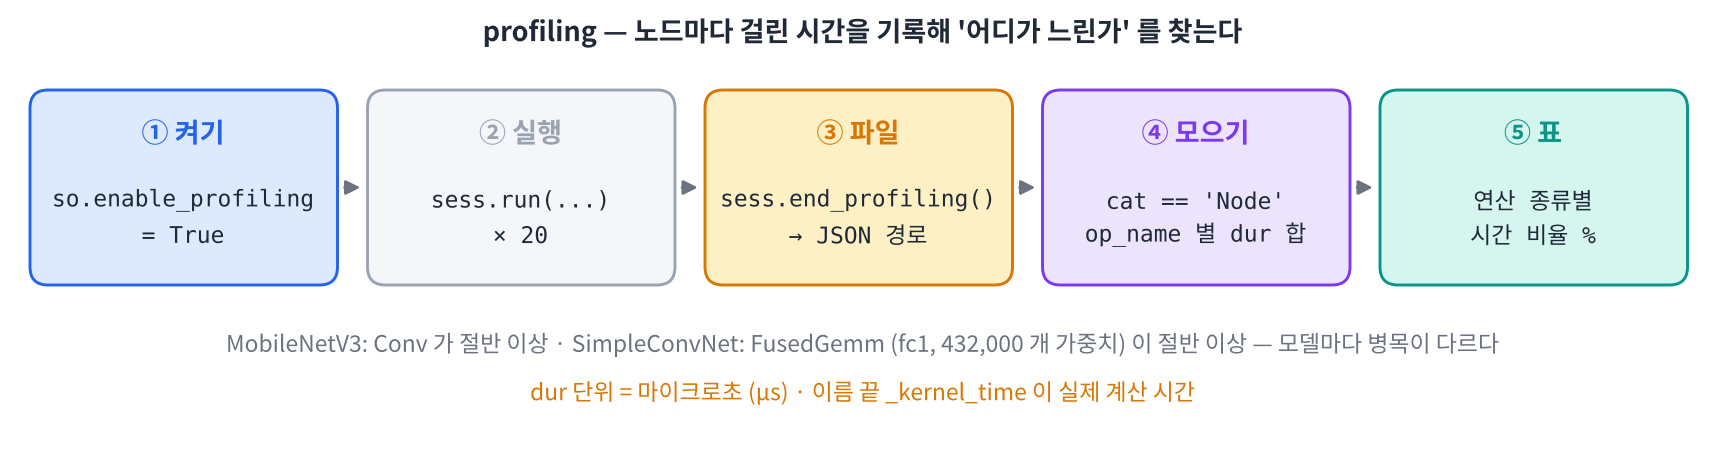

In [ ]:
#@title 🖼 그림 — profiling 다섯 단계
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day3/img/f7_profile.png", embed=True, width=880))

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `True`, `end_profiling` → 실행 예: 전체 기록 2882 · 노드 기록 2840 = **142 개 노드 × 20번** · 예 `Conv 153 µs [{'float': [1, 16, 112, 112]}]`.
- 142 개 ≠ 원래 127 개 — ALL 최적화 뒤의 그래프 (Reorder 노드 추가 등) 가 실행되기 때문. 4교시와 연결.

</div>

**문제 7-1** profiling 을 켠 세션으로 20번 실행한 뒤 `end_profiling()` 으로 파일을 닫고, JSON 을 읽어 **노드 실행 기록**만 골라내세요. 노드 기록은 `cat == "Node"` 이고 이름이 `_kernel_time` 으로 끝납니다.

In [ ]:
ps = make_session("mnv3s.onnx", profile=True)
for _ in range(20):
    ps.run(None, {"input": x1})
prof_path = ps.end_profiling()
events = json.load(open(prof_path))
node_ev = [e for e in events if e.get("cat") == "Node" and e["name"].endswith("_kernel_time")]
print(prof_path, "| 전체 기록", len(events), "| 노드 기록", len(node_ev))
print("예:", node_ev[0]["args"]["op_name"], node_ev[0]["dur"], "µs", node_ev[0]["args"]["output_type_shape"])

onnxruntime_profile__2026-11-06_10-44-26_277.json | 전체 기록 2882 | 노드 기록 2840
예: Conv 153 µs [{'float': [1, 16, 112, 112]}]


In [ ]:
assert len(node_ev) > 0 and len(node_ev) % 20 == 0 and all("op_name" in e["args"] for e in node_ev)
print("✅ 노드 기록 =", len(node_ev) // 20, "개 노드 × 20번")

✅ 노드 기록 = 142 개 노드 × 20번


<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `"op_name"`, `100` → 실행 예: Conv 53.3% · Mul 14.5% · Gemm 13.8% · HardSigmoid 8.4% · ReorderOutput 4.5% · ReorderInput 3.2%.
- Mul · HardSigmoid 가 보이는 이유 (물으면): ORT 가 HardSwish 를 HardSigmoid × x 로 실행하고, SE 블록에도 곱셈이 있음.

</div>

**문제 7-2** 연산 종류 (`op_name`) 별로 `dur` 을 더해 **시간 비율 (%)** 표를 만드세요. 가장 오래 걸리는 연산은?

In [ ]:
agg = collections.Counter()
for e in node_ev:
    agg[e["args"]["op_name"]] += e["dur"]
total = sum(agg.values())
df_prof = pd.DataFrame([{"op": k, "ms_per_run": v / 20 / 1000, "share_%": v / total * 100} for k, v in agg.most_common()])
display(df_prof.head(6))

,op,ms_per_run,share_%
0,Conv,1.26,53.32
1,Mul,0.34,14.49
2,Gemm,0.33,13.77
3,HardSigmoid,0.20,8.44
4,ReorderOutput,0.11,4.50
5,ReorderInput,0.07,3.17


In [ ]:
assert abs(df_prof["share_%"].sum() - 100) < 1e-6 and df_prof.op.iloc[0] == max(agg, key=agg.get)
print("✅ 1위:", df_prof.op.iloc[0], f"{df_prof['share_%'].iloc[0]:.0f}%")

✅ 1위: Conv 53%


<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `k` → 실행 예: MobileNetV3 `Conv 59.2 · Mul 13.4 · HardSigmoid 9.4` / SimpleConvNet `FusedGemm 51.0 · Conv 18.7 · MaxPool 11.8`.
- 2위 · 3위 순서는 실행마다 바뀔 수 있음 (Mul · Gemm · HardSigmoid 가 비슷 — 7-2 와 7-3 사이에서도 바뀜). 1위는 안정적.
- **Day 2 와 연결**: SimpleConvNet 의 FusedGemm = fc1 (432,000 개 가중치) — describe_onnx 의 params 열에서 짐작한 병목이 profiling 으로 확인됨.

</div>

**문제 7-3** 7-1 · 7-2 를 함수 `profile_top(path, x, k)` 로 묶어 **상위 k 개 연산 표**를 돌려주게 하고, SimpleConvNet 에도 적용해 보세요. 두 모델의 1위가 같은가요?

In [ ]:
def profile_top(path, x, k=3, n=20):
    s_ = make_session(path, profile=True)
    name = s_.get_inputs()[0].name
    for _ in range(n):
        s_.run(None, {name: x})
    ev = json.load(open(s_.end_profiling()))
    ag = collections.Counter()
    for e in ev:
        if e.get("cat") == "Node" and e["name"].endswith("_kernel_time"):
            ag[e["args"]["op_name"]] += e["dur"]
    tot = sum(ag.values())
    return pd.DataFrame([{"op": o, "share_%": v / tot * 100} for o, v in ag.most_common(k)])

top_mn = profile_top("mnv3s.onnx", x1)
top_cnn = profile_top("mnist_cnn_dyn.onnx", xm)
print("MobileNetV3  :", top_mn.round(1).values.tolist())
print("SimpleConvNet:", top_cnn.round(1).values.tolist())

MobileNetV3  : [['Conv', 59.2], ['Mul', 13.4], ['HardSigmoid', 9.4]]
SimpleConvNet: [['FusedGemm', 51.0], ['Conv', 18.7], ['MaxPool', 11.8]]


In [ ]:
assert len(top_mn) == 3 and len(top_cnn) == 3 and top_mn["share_%"].is_monotonic_decreasing
print("✅ 1위 — MobileNetV3:", top_mn.op.iloc[0], "| SimpleConvNet:", top_cnn.op.iloc[0], "→ 모델마다 병목이 다르다")

✅ 1위 — MobileNetV3: Conv | SimpleConvNet: FusedGemm → 모델마다 병목이 다르다


#### ⚠️ 자주 하는 실수

- `end_profiling()` 을 부르지 않고 파일을 찾음 → 파일이 닫히지 않아 내용이 없습니다.
- profiling 켠 세션으로 속도를 잼 → 기록하느라 느려집니다. **재는 세션과 기록하는 세션은 따로.**
- `dur` 단위를 ms 로 착각 → µs (1000 µs = 1 ms).

#### 📌 7교시 정리

- `enable_profiling=True` → run → `end_profiling()` → JSON → `cat == "Node"` · `op_name` 별 `dur` 합.
- MobileNetV3 = Conv, SimpleConvNet = FusedGemm — 병목은 모델마다 다르다. Day 4 · Quantization 의 출발점.

## 8교시 — 미니 프로젝트: 현장 카메라 4대용 설정 정하기

현장에 카메라 **4대** (각 30 FPS) 를 설치하고, MobileNetV3 분류기를 **CPU 한 대**로 돌리려 합니다. 오늘 배운 손잡이로 설정을 실험하고, 결과를 **성능표 파일** `ot_baseline.csv` 로 남긴 뒤 추천 설정을 씁니다.

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | `bench_config` — 설정 한 줄을 받아 측정 한 줄을 돌려주는 함수 | 20 |
| 2 | 실험표 — 스레드 1 · 2 × 레벨 DISABLE · ALL (배치 1) | 20 |
| 3 | 최선 설정에서 배치 1 · 4 · 8 — 처리량 | 20 |
| 4 | 최선 설정의 profiling — 느린 연산 Top 3 | 20 |
| 5 | `ot_baseline.csv` 저장 · 그래프 | 10 |
| 6 | 추천 설정과 근거 (마크다운 답변) | 10 |

시간 숫자는 사람마다 다르므로 채점은 **방법과 일관성**만 봅니다 (예: '최선' 이 정말 표에서 가장 작은 p95 인가).

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

**시간** 17:00–17:05 과제 설명 (카메라 4대 × 30 FPS = 120 장/초 판서) → 17:05–17:40 개인 실습 → 17:40–17:50 채점 셀 확인 · 제출 · Day 4 예고.

**채점 방식 안내**: 자동 90점은 **방법과 일관성**만 검사합니다 (예: best 가 정말 표의 p95 최소 줄인가). 시간 숫자가 크든 작든 점수와 무관하다고 먼저 말해 두면 질문이 줄어듭니다. 과제 6 (10점) 은 강사가 아래 모범 답안 기준으로 채점.

**서버 실행 예 (참고)**: grid — t1 DISABLE p95 6.05 · t1 ALL 1.98 · t2 DISABLE 4.03 · **t2 ALL 1.80 (최선)** / 배치 1 · 4 · 8 → 643 · 933 · 1059 장/초 → chosen_batch 1 / Top 3 Conv 49% · Mul 16% · HardSigmoid 12%. (다른 실행에서는 최선이 1 스레드 · ALL — 둘 다 정상) / CSV 7줄 (Colab GPU 면 8줄).

</div>

> 🎬 **애니메이션** [D3-8 카메라 4대 설정 정하기](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/animation.html#d3-8)
> 📝 **워크시트** [8교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day3/worksheet.html#t8)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

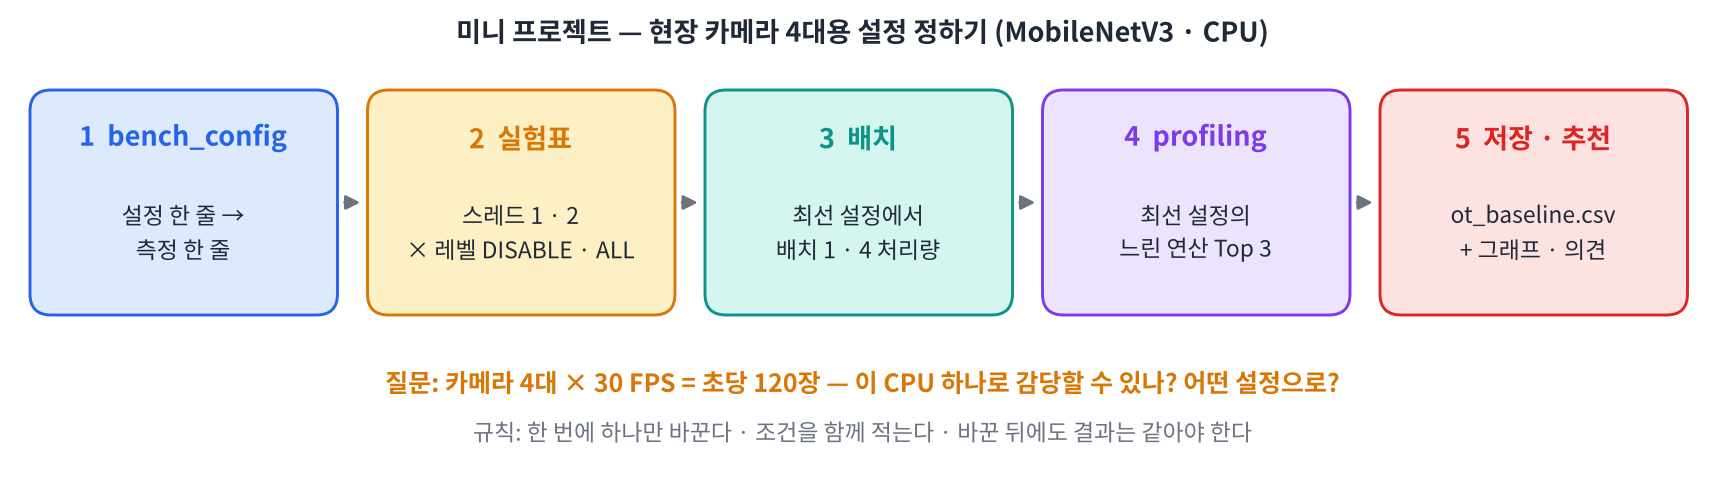

In [ ]:
#@title 🖼 그림 — 미니 프로젝트 흐름
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day3/img/f8_project.png", embed=True, width=880))

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `threads=threads, level=level`, `"batch": batch`. 채점 셀은 배치 2 로 다시 불러 `fps == 2000 / mean` 까지 검사 — `bench` 의 `× x.shape[0]` 이 맞아야 통과.
- 흔한 실수: `make_session(path)` 만 쓰고 인자를 안 넘김 → 표의 조건 열과 실제 세션이 달라짐 (채점은 통과할 수 있지만 표가 거짓말). 돌아다니며 확인하세요.

</div>

### 과제 1 — `bench_config` (20점)

설정 (`threads` · `level` · `batch`) 을 받아 세션을 만들고 `bench` 한 뒤, **조건 + 결과** 를 한 딕셔너리로 돌려주는 함수를 완성하세요. 열: `model` · `provider` · `threads` · `level` · `batch` · `mean` · `p50` · `p95` · `fps`.

In [ ]:
def bench_config(path, threads=0, level="ALL", batch=1, n=50):
    s_ = make_session(path, threads=threads, level=level)
    x_ = np.random.rand(batch, 3, 224, 224).astype(np.float32)
    r = bench(s_, x_, n=n, warm=5)
    return {"model": os.path.basename(path), "provider": s_.get_providers()[0], "threads": threads,
            "level": level, "batch": batch, **r}

print(bench_config("mnv3s.onnx", threads=1, level="DISABLE"))

{'model': 'mnv3s.onnx', 'provider': 'CPUExecutionProvider', 'threads': 1, 'level': 'DISABLE', 'batch': 1, 'mean': np.float64(5.152725459997782), 'p50': np.float64(5.1305970000044), 'p95': np.float64(5.281659150000451), 'fps': np.float64(194.07205133735775)}


<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `lv`, `idxmin`. `best` 는 Series (한 줄) — `best.threads` 가 numpy 값이라 `int()` 로 감싸는 것.
- 레벨 효과 (DISABLE → ALL 약 3배) 가 스레드 효과보다 큼 → 과제 6-2 의 답. 실행 예에서 스레드 효과는 DISABLE 에서 1.5배 (5.29 → 3.59), ALL 에서 10% 남짓 (1.78 → 1.60) — '한 손잡이의 효과가 다른 손잡이 설정에 따라 달라진다' 는 것도 짚을 만합니다.

</div>

### 과제 2 — 실험표 (20점)

스레드 {1, 2} × 레벨 {DISABLE, ALL} 네 가지를 배치 1 로 재서 `grid` 표를 만들고, **p95 가 가장 작은 줄**을 `best` 로 고르세요.

In [ ]:
rows = []
for th in [1, 2]:
    for lv in ["DISABLE", "ALL"]:
        rows.append(bench_config("mnv3s.onnx", threads=th, level=lv))
grid = pd.DataFrame(rows)
best = grid.loc[grid["p95"].idxmin()]
display(grid[["threads", "level", "mean", "p50", "p95", "fps"]])
print("최선:", int(best.threads), "스레드 ·", best.level, f"· p95 {best.p95:.2f} ms")

,threads,level,mean,p50,p95,fps
0,1,DISABLE,5.29,5.19,6.05,188.89
1,1,ALL,1.78,1.75,1.98,561.03
2,2,DISABLE,3.59,3.51,4.03,278.32
3,2,ALL,1.60,1.58,1.80,623.91


최선: 2 스레드 · ALL · p95 1.80 ms


<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `120`. Colab CPU 에서 배치 1 이 120 장/초를 넘는 것이 보통 (실행 예 643) → chosen_batch 1.
- None 이 나와도 채점은 통과 (일관성만 검사). 그 학생에게는 과제 6-4 를 꼭 쓰게 하세요.

</div>

### 과제 3 — 배치와 처리량 (20점)

`best` 의 스레드 · 레벨 그대로 배치 1 · 4 · 8 을 재서 `batch_tbl` 을 만들고, 카메라 4대 (초당 120장) 를 감당하는 배치 중 **지연 (mean) 이 가장 짧은 배치** `chosen_batch` 를 고르세요. 감당하는 배치가 없으면 `None`.

In [ ]:
batch_tbl = pd.DataFrame([bench_config("mnv3s.onnx", threads=int(best.threads), level=best.level, batch=b, n=30) for b in [1, 4, 8]])
ok = batch_tbl[batch_tbl["fps"] >= 120]                     # 카메라 4대 × 30 FPS
chosen_batch = int(ok.loc[ok["mean"].idxmin(), "batch"]) if len(ok) else None
display(batch_tbl[["batch", "mean", "p95", "fps"]])
print("카메라 4대 감당 · 지연 최소 배치:", chosen_batch)

,batch,mean,p95,fps
0,1,1.55,1.74,643.33
1,4,4.29,4.63,933.37
2,8,7.55,8.71,1058.91


카메라 4대 감당 · 지연 최소 배치: 1


<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `"dur"`, `3`. `best` 설정 그대로 profiling 해야 함 (7-3 의 `profile_top` 은 기본 설정이라 일부러 직접 쓰게 함).

</div>

### 과제 4 — profiling Top 3 (20점)

`best` 설정의 세션으로 profiling 해 **시간 비율 상위 3개 연산 이름**을 `top3` 리스트로 만드세요. (7-3 의 `profile_top` 은 기본 설정 세션이므로, 여기서는 직접 씁니다.)

In [ ]:
ps8 = make_session("mnv3s.onnx", threads=int(best.threads), level=best.level, profile=True)
for _ in range(20):
    ps8.run(None, {"input": x1})
ev8 = json.load(open(ps8.end_profiling()))
ag8 = collections.Counter()
for e in ev8:
    if e.get("cat") == "Node" and e["name"].endswith("_kernel_time"):
        ag8[e["args"]["op_name"]] += e["dur"]
top3 = [op for op, _ in ag8.most_common(3)]
print("Top 3:", top3, [f"{ag8[o] / sum(ag8.values()) * 100:.0f}%" for o in top3])

Top 3: ['Conv', 'Mul', 'HardSigmoid'] ['49%', '16%', '12%']


<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 정답: `"ot_baseline.csv"`. GPU 줄은 `table.loc[len(table)] = {...}` 로 한 줄 추가 — 채점 대상 아님.
- **Drive 저장 안내**: Day 4 에서 이 CSV 에 TensorRT 줄을 이어 붙입니다. 왼쪽 파일 탭에서 다운로드하거나 Drive 에 복사하게 하세요 (Colab 런타임이 끊기면 사라짐).

</div>

### 과제 5 — 성능표 저장 · 그래프 (10점)

`grid` 와 `batch_tbl` 을 합쳐 (`pd.concat`) **`ot_baseline.csv`** 로 저장하고, 설정별 p95 막대그래프를 그리세요. GPU 가 있으면 GPU 줄도 하나 추가합니다 (채점 대상 아님). 이 파일은 Day 4 TensorRT 결과를 같은 열로 이어 붙입니다.

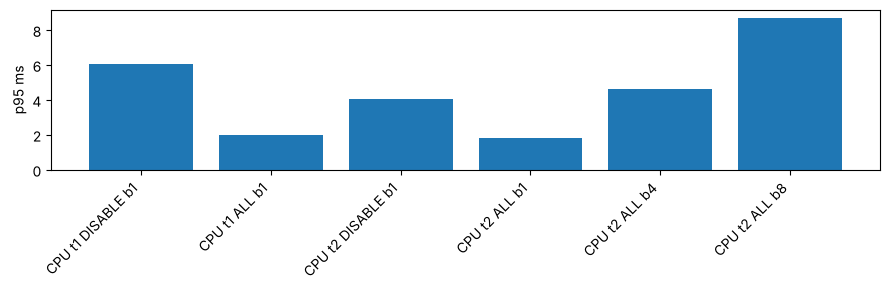

,model,provider,threads,level,batch,mean,p50,p95,fps
0,mnv3s.onnx,CPUExecutionProvider,1,DISABLE,1,5.29,5.19,6.05,188.89
1,mnv3s.onnx,CPUExecutionProvider,1,ALL,1,1.78,1.75,1.98,561.03
2,mnv3s.onnx,CPUExecutionProvider,2,DISABLE,1,3.59,3.51,4.03,278.32
3,mnv3s.onnx,CPUExecutionProvider,2,ALL,1,1.60,1.58,1.80,623.91
4,mnv3s.onnx,CPUExecutionProvider,2,ALL,1,1.55,1.54,1.74,643.33
5,mnv3s.onnx,CPUExecutionProvider,2,ALL,4,4.29,4.23,4.63,933.37
6,mnv3s.onnx,CPUExecutionProvider,2,ALL,8,7.55,7.03,8.71,1058.91


In [ ]:
table = pd.concat([grid, batch_tbl], ignore_index=True)
if GPU_OK:
    gs = make_session("mnv3s.onnx", providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
    table.loc[len(table)] = {"model": "mnv3s.onnx", "provider": gs.get_providers()[0], "threads": 0, "level": "ALL", "batch": 1, **bench(gs, x1, n=50)}
table.to_csv("ot_baseline.csv", index=False)
labels_ = [f"{r.provider[:3]} t{r.threads} {r.level} b{r.batch}" for r in table.itertuples()]
plt.figure(figsize=(9, 3)); plt.bar(labels_, table.p95); plt.xticks(rotation=45, ha="right"); plt.ylabel("p95 ms"); plt.tight_layout(); plt.show()
display(pd.read_csv("ot_baseline.csv"))

### 과제 6 — 추천 설정과 근거 (10점)

아래 셀에 답을 쓰세요. **숫자로** 근거를 대면 가점입니다.

1. 카메라 4대용으로 추천하는 설정 (스레드 · 레벨 · 배치) 과 그 근거를 `ot_baseline.csv` 의 숫자로 쓰세요.
2. 과제 2 에서 레벨과 스레드 중 무엇이 p95 에 더 큰 영향을 줬나요? '한 번에 하나만 바꾼다' 원칙으로 어떻게 알 수 있었나요?
3. 과제 4 의 Top 3 를 보고, 더 빠르게 하려면 어디를 손대야 할지 쓰세요. (힌트: Day 4 · Quantization)
4. 감당이 안 되거나 아슬아슬하다면 CPU 한 대로 해결할 수 있는 방법 2가지와, 장치를 바꾸는 방법 1가지를 쓰세요.

✍️ *여기에 답을 쓰세요.*

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

**과제 6 모범 답안**

1. (실행 예) 2 스레드 · ALL · 배치 1 (1 스레드와 차이는 작아 실행마다 바뀜) — p95 가 가장 작고, 배치 1 처리량이 120 장/초를 넘으면 프레임마다 바로 처리할 수 있어 지연도 가장 짧습니다. 배치 1 이 120 장/초에 못 미치면 처리량을 만족하는 가장 작은 배치를 고르고, 늘어나는 지연 (모으는 시간 + 배치 지연) 을 함께 적습니다.

2. 보통 레벨 (DISABLE → ALL) 의 영향이 훨씬 큽니다 (실행 예 약 3배. 스레드는 DISABLE 에서 1.5배, ALL 에서 10% 남짓). 스레드를 고정하고 레벨만 바꾼 두 줄, 레벨을 고정하고 스레드만 바꾼 두 줄을 비교했기 때문에 각각의 효과를 따로 읽을 수 있습니다.

3. Conv 가 절반 이상 → Conv 를 빠르게: GPU (TensorRT, Day 4), FP16 · INT8 정밀도 (Day 4 · 11/16 Quantization), 채널 수를 줄이는 Pruning.

4. CPU 한 대: 입력 크기 줄이기 (224 → 160), 프레임 건너뛰기 (2장 중 1장만), 카메라 프레임을 모아 배치 처리, 스레드 · 레벨 재확인. 장치: GPU (Jetson 의 TensorRT · Day 4) 또는 장치를 늘려 카메라를 나눠 맡기기.

</div>

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

- 서버 실행 결과: 자동 채점 **90 / 90**. 각 과제가 앞 과제의 변수 (`best` · `batch_tbl` · `ag8`) 를 쓰므로 런타임이 끊겼으면 과제 1 → 5 순서로 다시.
- 제출: 채점 셀 결과 + 과제 6 답이 보이는 상태로 '공유' 링크 제출 (Day 1 · 2 와 같은 방식).

</div>

### 채점 셀

In [ ]:
score = 0
try:
    r1 = bench_config("mnv3s.onnx", threads=1, level="ALL", batch=2, n=5)
    assert {"model", "provider", "threads", "level", "batch", "mean", "p50", "p95", "fps"} <= set(r1)
    assert r1["batch"] == 2 and r1["threads"] == 1 and r1["level"] == "ALL" and abs(r1["fps"] - 2000 / r1["mean"]) < 1e-6
    score += 20; print("✅ 과제 1  +20")
except Exception as e: print("❌ 과제 1", e)
try:
    assert len(grid) == 4 and set(zip(grid.threads, grid.level)) == {(1, "DISABLE"), (1, "ALL"), (2, "DISABLE"), (2, "ALL")}
    assert set(grid.batch) == {1} and best.p95 == grid.p95.min()
    score += 20; print("✅ 과제 2  +20", f"(최선 {int(best.threads)} 스레드 · {best.level})")
except Exception as e: print("❌ 과제 2", e)
try:
    assert batch_tbl.batch.tolist() == [1, 4, 8] and set(batch_tbl.threads) == {int(best.threads)} and set(batch_tbl.level) == {best.level}
    ok_ = batch_tbl[batch_tbl.fps >= 120]
    assert chosen_batch == (int(ok_.loc[ok_["mean"].idxmin(), "batch"]) if len(ok_) else None)
    score += 20; print("✅ 과제 3  +20", f"(선택 배치 {chosen_batch})")
except Exception as e: print("❌ 과제 3", e)
try:
    assert len(top3) == 3 and top3 == [o for o, _ in ag8.most_common(3)] and all(isinstance(o, str) for o in top3)
    score += 20; print("✅ 과제 4  +20", top3)
except Exception as e: print("❌ 과제 4", e)
try:
    t5 = pd.read_csv("ot_baseline.csv")
    assert {"model", "provider", "threads", "level", "batch", "mean", "p95", "fps"} <= set(t5.columns) and len(t5) >= 7
    score += 10; print("✅ 과제 5  +10", f"({len(t5)}줄)")
except Exception as e: print("❌ 과제 5", e)
print(f"\n자동 채점 {score} / 90  (+ 과제 6 강사 채점 10점)")

✅ 과제 1  +20
✅ 과제 2  +20 (최선 2 스레드 · ALL)
✅ 과제 3  +20 (선택 배치 1)
✅ 과제 4  +20 ['Conv', 'Mul', 'HardSigmoid']
✅ 과제 5  +10 (7줄)

자동 채점 90 / 90  (+ 과제 6 강사 채점 10점)


#### 📌 8교시 정리

- 설정 = 조건 열 + 결과 열 한 줄. 표가 쌓이면 결정의 근거가 된다.
- 고르는 기준은 목적에 따라: 실시간 → p95 · 지연, 여러 카메라 → 처리량.
- `ot_baseline.csv` — 내일 TensorRT 결과를 같은 열로 이어 붙인다.

## 오늘의 정리

### 셀프 체크

- [ ] 첫 실행이 느린 이유와 warm-up 이 필요한 이유를 말할 수 있다
- [ ] 평균 · p50 · p95 · FPS 를 계산하고, 실시간 시스템에서 p95 를 보는 이유를 설명할 수 있다
- [ ] `bench()` 로 조건 + 결과 한 줄을 만들 수 있다
- [ ] `SessionOptions` 로 스레드 수를 바꾸고, 코어 수와의 관계를 설명할 수 있다
- [ ] 최적화 레벨 4단계가 각각 무엇을 하는지 (상수 접기 · 노드 합치기 · 레이아웃) 말할 수 있다
- [ ] `CUDAExecutionProvider` 로 GPU 를 쓰고 `get_providers()` 로 확인할 수 있다
- [ ] 지연과 처리량을 구분하고, 카메라 수를 계산할 수 있다
- [ ] profiling 으로 연산별 시간 비율을 구할 수 있다
- [ ] '한 번에 하나만 · 조건을 함께 · 결과는 같게' 원칙으로 실험할 수 있다

### 다음 시간 (Day 4) 예고

7교시에서 MobileNetV3 시간의 절반 이상이 **Conv** 였습니다. Day 4 에서는 같은 `mnv3s.onnx` 를 **TensorRT 엔진**으로 바꿔 GPU 전용으로 다시 조립하고, **FP16** 으로 더 빠르게 만듭니다. 오늘 만든 **`bench` · `ot_baseline.csv`** 에 TensorRT 줄을 이어 붙입니다 — Drive 에 노트북과 CSV 를 꼭 저장해 두세요.

<div style="border-left:6px solid #e8a33d;background:#fff8ec;padding:10px 14px;color:#222">

**👩‍🏫 강사 노트**

**마무리 (17:45)**: 셀프 체크 9개를 소리 내어 읽고 손들기 — 2개 이상 손을 못 든 항목은 워크시트 해당 교시 (#tN) 를 숙제로.

**Day 4 예고 한 문장**: "오늘 찾은 병목 Conv 를, 내일은 TensorRT 가 GPU 전용으로 다시 조립합니다. 오늘 만든 bench 와 CSV 그대로 씁니다."

</div>